# Demand Analysis

This analysis explores historical retail demand patterns across time, products, categories, departments, stores, states, events, and prices.

The analysis is designed to answer **Business Question 1**:

> What does retail demand look like and what patterns exist?

## 1. Load Prepared Data

The analysis uses:

- Historical sales: daily demand from `d_1` to `d_1913`
- Calendar: dates, weekdays, months, years, events, and SNAP indicators
- Selling prices: product-store-week selling prices

The datasets are kept separate and will be joined only when required for a specific analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sales_historical = pd.read_csv(
    "../data/processed/analytical/sales_historical.csv"
)

calendar = pd.read_csv(
    "../data/processed/cleaned/calendar.csv",
    parse_dates=["date"]
)

selling_prices = pd.read_csv(
    "../data/raw/sell_prices.csv"
)

In [4]:
print("Historical sales:", sales_historical.shape)
print("Calendar:", calendar.shape)
print("Selling prices:", selling_prices.shape)

Historical sales: (58327370, 8)
Calendar: (1969, 14)
Selling prices: (6841121, 4)


## 2. Overall Demand Understanding

### 2.1 Overall Demand Overview

First, we establish the basic demand picture across all products and stores during the historical period.

We will examine:

- Total units sold
- Average daily demand
- Median daily demand
- Minimum / Maximum daily demand
- Demand distribution
- Demand variability (Standard Deviation, Coefficient of Variation - CV)

**Business Question:**

> What does overall retail demand look like?

In [5]:
# one day = one row

daily_demand = (
    sales_historical
    .groupby("d", as_index=False)["demand"]
    .sum()
)

#### 2.1.1 Basic Overall Demand Metrics

In [6]:
overall_demand_summary = {
    "Total units sold": daily_demand["demand"].sum(),
    "Average daily demand": daily_demand["demand"].mean(),
    "Median daily demand": daily_demand["demand"].median(),
    "Minimum daily demand": daily_demand["demand"].min(),
    "Maximum daily demand": daily_demand["demand"].max(),
}

overall_demand_summary

{'Total units sold': np.int64(65695409),
 'Average daily demand': np.float64(34341.562467328804),
 'Median daily demand': np.float64(33732.0),
 'Minimum daily demand': np.int64(11),
 'Maximum daily demand': np.int64(57218)}

##### Basic Overall Demand Metrics — Key Observations

| Metric | Value | Business Meaning |
|---|---:|---|
| Total units sold | 65,695,409 | Total demand across all products and stores |
| Average daily demand | 34,342 | Average units sold per day |
| Median daily demand | 33,732 | Typical central daily demand |
| Minimum daily demand | 11 | Lowest total demand recorded on a day |
| Maximum daily demand | 57,218 | Highest total demand recorded on a day |

+ Daily demand ranged from 11 to 57,218 units, indicating substantial variation across the historical period.
+ The average being slightly higher than the median suggests that higher-demand days influence the overall average.

#### 2.1.2 Demand Distribution

The distribution of total daily demand shows how demand is spread across the historical period and whether unusually high or low demand days are influencing the overall demand pattern.

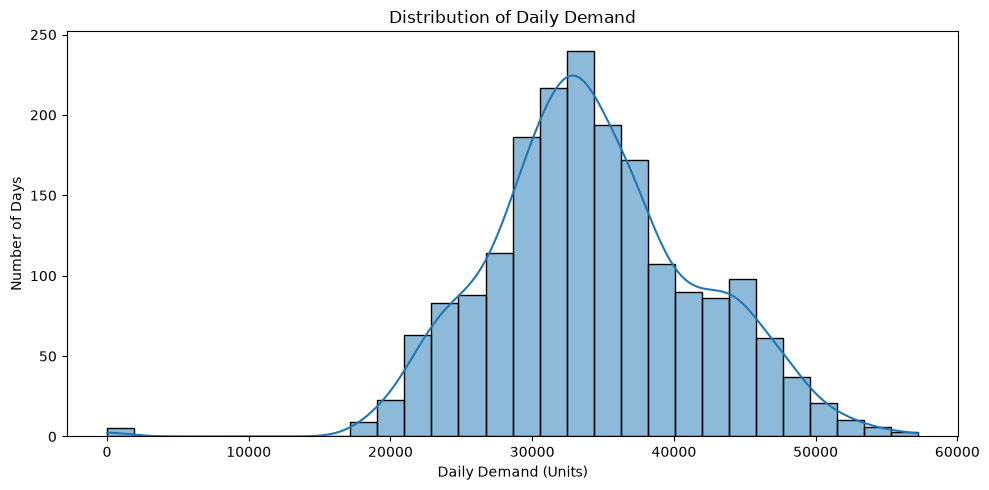

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    daily_demand["demand"],
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Demand")
plt.xlabel("Daily Demand (Units)")
plt.ylabel("Number of Days")
plt.tight_layout()
plt.show()

##### Overall Demand Distribution — Key Observations

- Most daily demand falls between approximately **25,000 and 45,000 units**.
- Demand is most concentrated around **30,000–35,000 units**.
- Very few days have extremely low or extremely high demand.
- The distribution has one main peak, showing a **broadly unimodal demand pattern**.
- The very low-demand observations will be examined further during **time-based analysis**.

#### 2.1.3 Demand Variability

Demand variability helps us understand how consistently the total daily demand changes around its typical level.

In [8]:
demand_std = daily_demand["demand"].std()

demand_cv = (
    daily_demand["demand"].std()
    / daily_demand["demand"].mean()
)

print("Standard deviation:", demand_std)
print("Coefficient of variation:", demand_cv)

Standard deviation: 7345.905196022218
Coefficient of variation: 0.21390713375405734


##### Demand Variability — Key Observations

- The standard deviation of daily demand is approximately **7,346 units**
- Daily demand has a coefficient of variation of approximately **21.4%**, indicating measurable variation around the average daily demand level.
- This establishes that demand is not completely stable and that variability should be considered when analyzing demand patterns and developing the forecast.

### 2.2 Demand Trend Over Time

This section examines how retail demand changes over the historical period at different time levels.

The analysis focuses on:

- Daily demand
- Weekly demand
- Monthly demand
- Yearly demand

For each time level, we examine changes in demand, major increases and decreases, and overall trends using appropriate statistics and visualizations.

**Business Questions:**

> How does demand change over time?
- Is demand generally increasing, declining, or stable?
- Are there periods of unusually high or low demand?

In [9]:
daily_demand = daily_demand.merge(
    calendar[["d", "date"]],
    on="d",
    how="left"
)

daily_demand = daily_demand.sort_values("date")

#### 2.2.1 Daily Demand Trend

Daily demand provides the most detailed view of how demand changes from one day to the next.

We will examine:

- Day-to-day demand changes
- Major demand increases and decreases
- A 7-day rolling average to identify the underlying trend

In [10]:
# Today's demand − Previous day's demand

daily_demand["demand_change"] = (
    daily_demand["demand"].diff()
)

In [11]:
daily_demand["demand_change"].describe()

count     1912.000000
mean         8.976987
std       5927.556209
min     -36213.000000
25%      -2486.250000
50%        125.000000
75%       3535.250000
max      38363.000000
Name: demand_change, dtype: float64

In [12]:
# 10 largest absolute increases in daily demand

daily_demand.nlargest(
    10,
    "demand_change"
)[["date", "demand", "demand_change"]]

,date,demand,demand_change
882,2015-12-26,38377,38363.0
477,2014-12-26,32909,32889.0
72,2013-12-26,32727,32707.0
1578,2012-12-26,29701,29690.0
1173,2011-12-26,28032,28019.0
89,2014-01-11,47798,15032.0
929,2016-02-06,55040,14847.0
525,2015-02-07,50836,14027.0
898,2016-01-09,52880,13944.0
517,2015-01-31,50828,13388.0


In [13]:
# 10 largest absolute decreases in daily demand

daily_demand.nsmallest(
    10,
    "demand_change"
)[["date", "demand", "demand_change"]]

,date,demand,demand_change
881,2015-12-25,14,-36213.0
1577,2012-12-25,11,-32612.0
71,2013-12-25,20,-31057.0
1172,2011-12-25,13,-29945.0
476,2014-12-25,20,-29597.0
688,2015-07-04,37489,-16665.0
962,2016-03-07,40562,-16656.0
849,2015-11-26,23631,-16493.0
41,2013-11-28,19839,-16300.0
993,2016-04-04,40418,-16007.0


In [14]:
# Create the 7-day rolling average

daily_demand["rolling_7d"] = (
    daily_demand["demand"]
    .rolling(7)
    .mean()
)

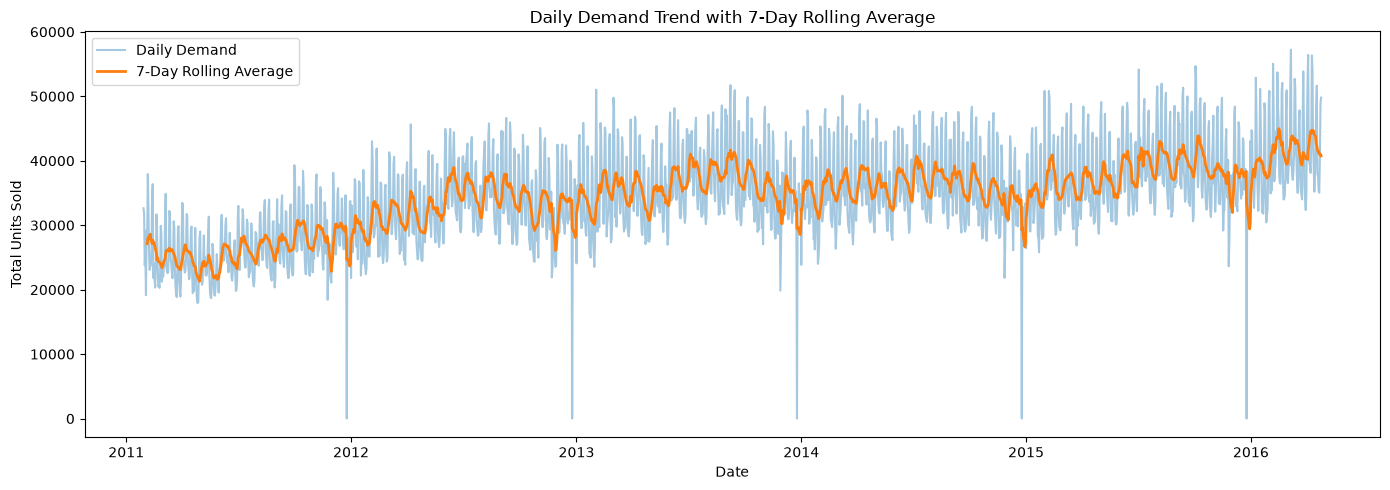

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand["date"],
    daily_demand["demand"],
    alpha=0.4,
    label="Daily Demand"
)

plt.plot(
    daily_demand["date"],
    daily_demand["rolling_7d"],
    linewidth=2,
    label="7-Day Rolling Average"
)

plt.title("Daily Demand Trend with 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

##### Daily Demand — Key Observations

- The 7-day rolling average shows an overall upward movement in demand across the historical period, although demand fluctuates considerably from day to day.
- The middle 50% of day-to-day demand changes range from approximately **-2,486 to +3,535 units**, showing meaningful short-term variation.
- The largest demand decreases occur repeatedly on **December 25**, while the largest increases occur on **December 26** across multiple years.
- This recurring December pattern indicates that calendar-related effects can create substantial short-term changes in demand and should be considered during forecasting.
- Several other unusually large increases and decreases occur on individual dates. Their underlying causes will be examined later through event, weekday, and seasonal analysis.

#### 2.2.2 Weekly Demand

Weekly aggregation reduces day-to-day fluctuations and provides a clearer view of how demand changes over longer periods.

We will examine:

- Weekly demand
- Week-to-week changes
- Major increases and decreases
- The overall weekly trend

In [16]:
# Create Weekly Demand

weekly_demand = (
    daily_demand
    .set_index("date")["demand"]
    .resample("W-SAT")
    .sum()
    .reset_index()
)

weekly_demand.head()

,date,demand
0,2011-01-29,32631
1,2011-02-05,195243
2,2011-02-12,190071
3,2011-02-19,179425
4,2011-02-26,167221


In [17]:
# Check number of days in each week

weekly_day_count = (
    daily_demand
    .set_index("date")["demand"]
    .resample("W-SAT")
    .count()
    .reset_index(name="days")
)

weekly_day_count.tail()

,date,days
270,2016-04-02,7
271,2016-04-09,7
272,2016-04-16,7
273,2016-04-23,7
274,2016-04-30,1


In [18]:
weekly_demand_complete = weekly_demand[
    weekly_day_count["days"] == 7
].copy()

In [19]:
# weekly demand change

weekly_demand_complete["demand_change"] = (
    weekly_demand_complete["demand"].diff()
)

In [20]:
weekly_demand_complete["demand_change"].describe()

count      272.000000
mean       337.797794
std      17508.192579
min     -38996.000000
25%     -13253.250000
50%      -2620.000000
75%      13710.000000
max      49336.000000
Name: demand_change, dtype: float64

In [21]:
# Largest weekly increases

weekly_demand_complete.nlargest(
    10,
    "demand_change"
)[["date", "demand", "demand_change"]]

,date,demand,demand_change
149,2013-12-07,261317,49336.0
175,2014-06-07,270629,42063.0
101,2013-01-05,240276,40367.0
227,2015-06-06,279849,39551.0
62,2012-04-07,247044,39513.0
97,2012-12-08,242571,38576.0
153,2014-01-04,241209,37596.0
179,2014-07-05,275671,37227.0
49,2012-01-07,205479,36048.0
123,2013-06-08,272882,35272.0


In [22]:
# Largest weekly decreases

weekly_demand_complete.nsmallest(
    10,
    "demand_change"
)[["date", "demand", "demand_change"]]

,date,demand,demand_change
152,2013-12-28,203613,-38996.0
256,2015-12-26,228515,-38091.0
100,2012-12-29,199909,-36940.0
48,2011-12-31,169431,-35434.0
204,2014-12-27,202226,-34617.0
169,2014-04-26,238271,-34104.0
212,2015-02-21,244392,-32782.0
164,2014-03-22,240391,-31452.0
73,2012-06-23,243825,-28777.0
125,2013-06-22,246805,-26959.0


##### Weekly Demand — Statistical Key Observations

- Week-to-week demand changes can be substantial, with the middle 50% of changes ranging from approximately **-13,253 to +13,710 units**.
- The largest weekly increases and decreases show that demand can change considerably between consecutive weeks.
- Several of the largest weekly decreases occur in **late December**, indicating a recurring period of substantial demand change.
- The reason for this recurring pattern will be investigated later using calendar and seasonal analysis.

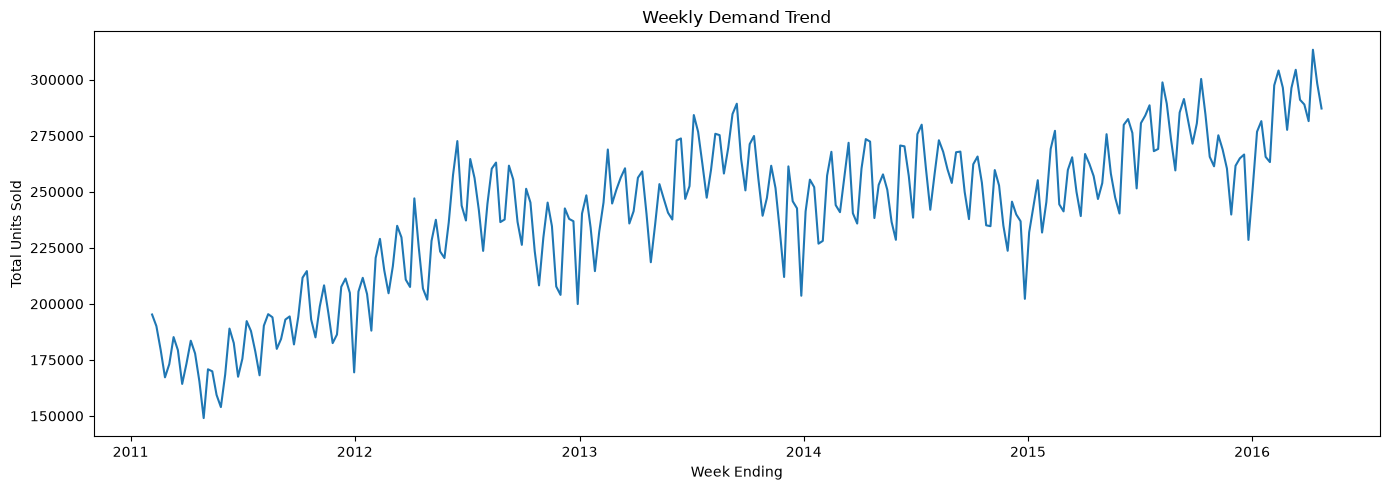

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    weekly_demand_complete["date"],
    weekly_demand_complete["demand"]
)

plt.title("Weekly Demand Trend")
plt.xlabel("Week Ending")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()

##### Weekly Demand — Visual Key Observations

- Weekly demand shows an overall upward trend across the historical period.
- Demand also fluctuates considerably from week to week, with recurring peaks and dips.
- The weekly aggregation makes the longer-term upward movement clearer than the daily demand series.
- The recurring fluctuations suggest that time-based patterns may be important when developing the demand forecast.

### 2.2.3 Monthly Demand

Monthly aggregation provides a broader view of demand over time and helps identify longer-term changes and recurring monthly patterns.

In [24]:
# Create Monthly Demand

monthly_demand = (
    daily_demand
    .set_index("date")["demand"]
    .resample("ME")
    .sum()
    .reset_index()
)

monthly_demand.head()

,date,demand
0,2011-01-31,88163
1,2011-02-28,726375
2,2011-03-31,763567
3,2011-04-30,737713
4,2011-05-31,719562


In [25]:
# Monthly Demand Change

monthly_demand["demand_change"] = (
    monthly_demand["demand"].diff()
)

monthly_demand["demand_change"].describe()

count        63.000000
mean      15214.682540
std      101395.455358
min     -229058.000000
25%      -37962.000000
50%        6077.000000
75%       59554.500000
max      638212.000000
Name: demand_change, dtype: float64

In [26]:
# Largets Monthly Increases

monthly_demand.nlargest(
    10,
    "demand_change"
)[["date", "demand", "demand_change"]]

,date,demand,demand_change
1,2011-02-28,726375,638212.0
38,2014-03-31,1123706,113946.0
26,2013-03-31,1117570,106910.0
17,2012-06-30,1095609,97863.0
60,2016-01-31,1215286,89050.0
14,2012-03-31,986894,88904.0
50,2015-03-31,1119727,87850.0
9,2011-10-31,898243,84560.0
54,2015-07-31,1232147,76548.0
23,2012-12-31,1030452,69768.0


In [27]:
# Largest Monthly Decreases

monthly_demand.nsmallest(
    10,
    "demand_change"
)[["date", "demand", "demand_change"]]

,date,demand,demand_change
63,2016-04-30,1046688,-229058.0
58,2015-11-30,1113976,-134461.0
44,2014-09-30,1088414,-95688.0
27,2013-04-30,1034036,-83534.0
34,2013-11-30,1044799,-79724.0
10,2011-11-30,823087,-75156.0
56,2015-09-30,1188913,-65428.0
21,2012-10-31,1006308,-58056.0
46,2014-11-30,1051078,-52000.0
49,2015-02-28,1031877,-51238.0


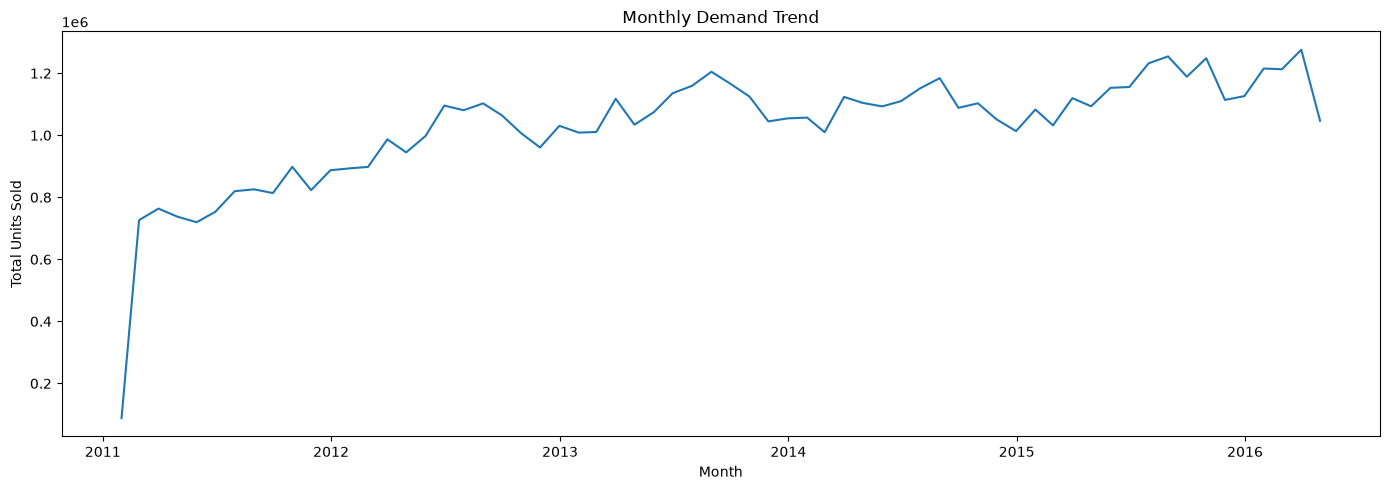

In [28]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_demand["date"],
    monthly_demand["demand"]
)

plt.title("Monthly Demand Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()

##### Monthly Demand — Key Observations

- Monthly demand shows an overall upward trend across the historical period, with noticeable fluctuations between months.
- Demand reaches a generally higher level in the later years, while month-to-month changes remain present throughout the period.
- The first month of the dataset and the final month are incomplete and should not be interpreted as normal full-month demand levels.
- The monthly trend shows changes over time, but recurring monthly seasonality will be examined separately using month-of-year analysis.

### 2.2.4 Yearly Demand

Yearly aggregation provides a high-level view of how total demand changes across the historical years.

In [29]:
# Create Yearly Demand

yearly_demand = (
    daily_demand
    .set_index("date")["demand"]
    .resample("YE")
    .sum()
    .reset_index()
)

yearly_demand

,date,demand
0,2011-12-31,8856585
1,2012-12-31,12061837
2,2013-12-31,13135753
3,2014-12-31,13089776
4,2015-12-31,13800811
5,2016-12-31,4750647


In [30]:
# Check number of days per year

yearly_day_count = (
    daily_demand
    .set_index("date")["demand"]
    .resample("YE")
    .count()
    .reset_index(name="days")
)

yearly_day_count

,date,days
0,2011-12-31,337
1,2012-12-31,366
2,2013-12-31,365
3,2014-12-31,365
4,2015-12-31,365
5,2016-12-31,115


In [31]:
yearly_demand_complete = yearly_demand[
    yearly_day_count["days"] >= 365
].copy()

yearly_demand_complete

,date,demand
1,2012-12-31,12061837
2,2013-12-31,13135753
3,2014-12-31,13089776
4,2015-12-31,13800811


In [32]:
# Calculate year-to-year demand change

yearly_demand_complete["demand_change"] = (
    yearly_demand_complete["demand"].diff()
)

yearly_demand_complete

,date,demand,demand_change
1,2012-12-31,12061837,NaN
2,2013-12-31,13135753,1073916.0
3,2014-12-31,13089776,-45977.0
4,2015-12-31,13800811,711035.0


In [33]:
# year-over-year percentage change

yearly_demand_complete["demand_change_pct"] = (
    yearly_demand_complete["demand_change"]
    / yearly_demand_complete["demand"].shift(1)
) * 100

yearly_demand_complete

,date,demand,demand_change,demand_change_pct
1,2012-12-31,12061837,NaN,NaN
2,2013-12-31,13135753,1073916.0,8.903420
3,2014-12-31,13089776,-45977.0,-0.350014
4,2015-12-31,13800811,711035.0,5.431988


##### Yearly Demand — Statistical Key Observations

- Annual demand increased by approximately **8.9%** from 2012 to 2013.
- Annual demand was relatively stable in 2014, with a slight **0.35% decrease** compared with 2013.
- Annual demand increased by approximately **5.4%** from 2014 to 2015.
- Overall, annual demand increased across the complete-year period, although the growth was not consistent every year.

In [34]:
yearly_demand["year"] = yearly_demand["date"].dt.year

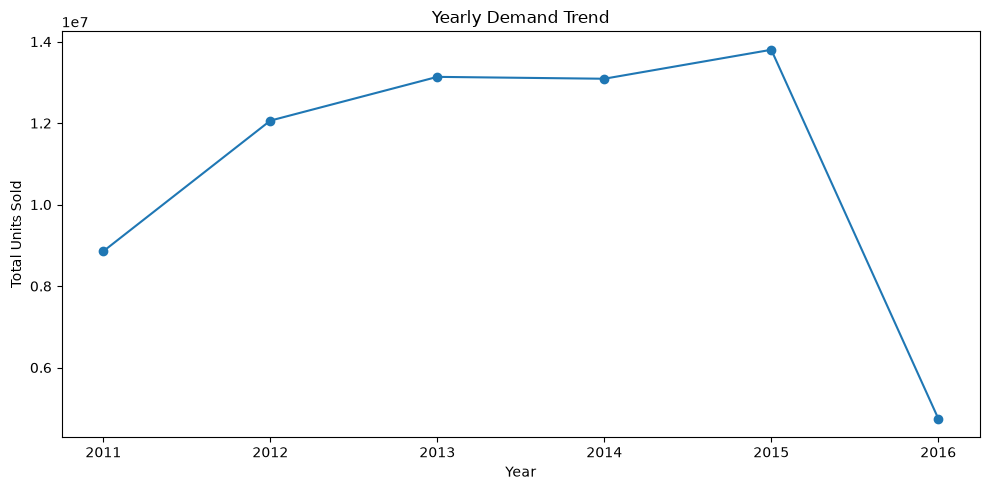

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_demand["year"],
    yearly_demand["demand"],
    marker="o"
)

plt.title("Yearly Demand Trend")
plt.xlabel("Year")
plt.ylabel("Total Units Sold")
plt.xticks(yearly_demand["year"])
plt.tight_layout()
plt.show()

##### Yearly Demand — Visual Key Observations

- Demand increased from **2012 to 2013**, with annual demand rising by approximately **8.9%**.
- Demand was almost stable from **2013 to 2014**, with a slight decrease of approximately **0.35%**.
- Demand increased again from **2014 to 2015**, rising by approximately **5.4%**.
- Overall, the complete years show an upward movement in annual demand, although growth was not consistent every year.
- The 2011 and 2016 totals are lower because these years contain only **337 and 115 days of data**, respectively, and should not be interpreted as full-year demand levels.

### 2.3 Time Patterns & Seasonality

This section focuses on recurring time-based patterns that may help explain predictable changes in demand and support the forecasting process.

We will examine:

- Day-of-week patterns
- Weekday versus weekend demand
- Month-of-year patterns
- Recurring seasonal peaks and drops

**Business Question:**

> Are there predictable time-based demand patterns that should be considered when forecasting?

#### 2.3.1 Day-of-week Demand

We first examine whether demand differs systematically across days of the week.

We will compare:

- Total demand
- Average daily demand
- Median daily demand
- Demand variability

In [36]:
# Add weekday information to daily_demand

daily_demand = daily_demand.merge(
    calendar[["d", "weekday"]],
    on="d",
    how="left"
)

daily_demand.head(10)

,d,demand,date,demand_change,rolling_7d,weekday
0,d_1,32631,2011-01-29,NaN,NaN,Saturday
1,d_2,31749,2011-01-30,-882.0,NaN,Sunday
2,d_3,23783,2011-01-31,-7966.0,NaN,Monday
3,d_4,25412,2011-02-01,1629.0,NaN,Tuesday
4,d_5,19146,2011-02-02,-6266.0,NaN,Wednesday
5,d_6,29211,2011-02-03,10065.0,NaN,Thursday
6,d_7,28010,2011-02-04,-1201.0,27134.571429,Friday
7,d_8,37932,2011-02-05,9922.0,27891.857143,Saturday
8,d_9,32736,2011-02-06,-5196.0,28032.857143,Sunday
9,d_10,25572,2011-02-07,-7164.0,28288.428571,Monday


In [37]:
weekday_demand = (
    daily_demand
    .groupby("weekday")["demand"]
    .agg(
        total_demand="sum",
        average_demand="mean",
        median_demand="median",
        demand_std="std"
    )
    .reset_index()
)

weekday_demand

,weekday,total_demand,average_demand,median_demand,demand_std
0,Friday,9343694,34225.985348,34775.0,5602.039850
1,Monday,8968860,32852.967033,33444.0,5223.531803
2,Saturday,11383849,41546.894161,42437.0,6120.410805
3,Sunday,11269626,41130.021898,42586.0,6997.727834
4,Thursday,8245967,30205.007326,30658.0,5342.799233
5,Tuesday,8290677,30368.780220,30710.0,5088.427937
6,Wednesday,8192736,30010.021978,30911.0,5164.106112


In [38]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_demand["weekday"] = pd.Categorical(
    weekday_demand["weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_demand = weekday_demand.sort_values("weekday")

In [39]:
weekday_demand

,weekday,total_demand,average_demand,median_demand,demand_std
1,Monday,8968860,32852.967033,33444.0,5223.531803
5,Tuesday,8290677,30368.780220,30710.0,5088.427937
6,Wednesday,8192736,30010.021978,30911.0,5164.106112
4,Thursday,8245967,30205.007326,30658.0,5342.799233
0,Friday,9343694,34225.985348,34775.0,5602.039850
2,Saturday,11383849,41546.894161,42437.0,6120.410805
3,Sunday,11269626,41130.021898,42586.0,6997.727834


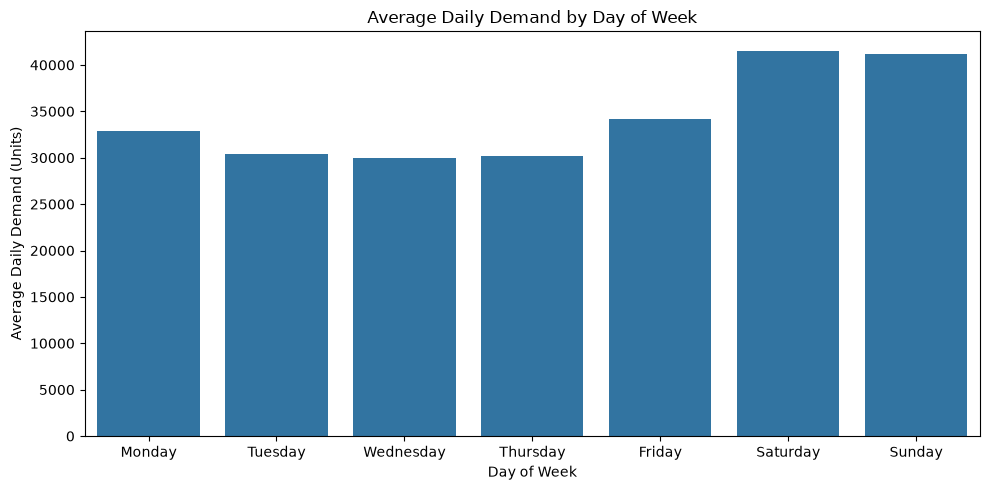

In [40]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_demand,
    x="weekday",
    y="average_demand"
)

plt.title("Average Daily Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Demand (Units)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

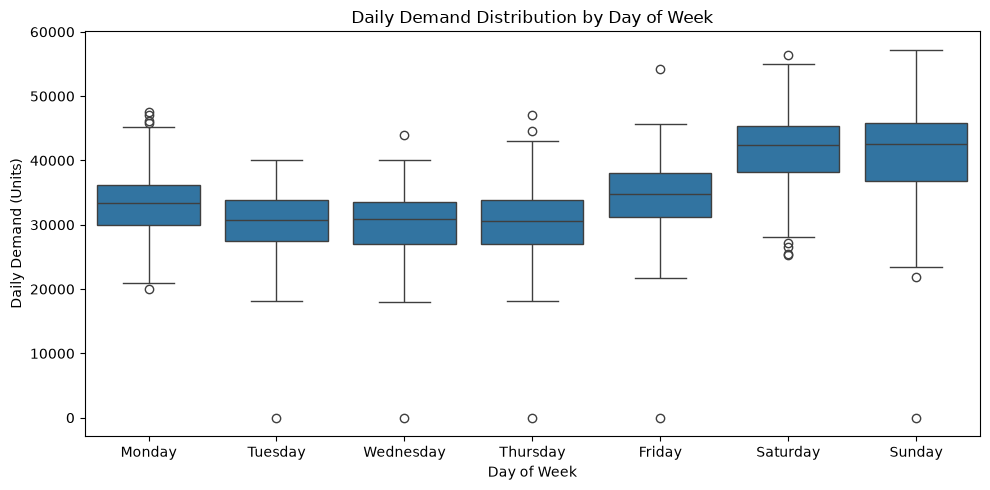

In [41]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=daily_demand,
    x="weekday",
    y="demand",
    order=weekday_order
)

plt.title("Daily Demand Distribution by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Daily Demand (Units)")
plt.tight_layout()
plt.show()

##### Day-of-week — Key Observations

- Demand varies noticeably across the days of the week, with **Saturday and Sunday showing the highest average demand** at approximately 41,547 and 41,130 units respectively.
- **Wednesday has the lowest average demand** at approximately 30,010 units, while Tuesday and Thursday are also relatively lower.
- The boxplot shows that weekend demand distributions are generally higher than weekday distributions, indicating that the weekend pattern is not driven only by a few extreme observations.
- Some unusually high and low demand days occur across the week, but the overall weekday pattern remains clear.
- The recurring difference in demand by day of week indicates that **weekly seasonality should be considered when developing the forecast**.

### 2.3.2 Weekday vs Weekend

The day-of-week analysis showed that demand differs across individual days mainly on weekend and weekday.

We now group the days into **Weekday** and **Weekend** to determine whether this difference remains when comparing the two broader time categories.

We will compare:

- Average demand
- Median demand
- Total demand
- Difference in average demand
- Demand distribution

In [42]:
daily_demand["day_type"] = np.where(
    daily_demand["weekday"].isin(["Saturday", "Sunday"]),
    "Weekend",
    "Weekday"
)

In [43]:
weekday_weekend = (
    daily_demand
    .groupby("day_type")["demand"]
    .agg(
        total_demand="sum",
        average_demand="mean",
        median_demand="median",
        demand_std="std"
    )
    .reset_index()
)

weekday_weekend

,day_type,total_demand,average_demand,median_demand,demand_std
0,Weekday,43041934,31532.552381,31995.0,5546.302073
1,Weekend,22653475,41338.458029,42526.5,6571.022386


In [44]:
weekday_avg = weekday_weekend.loc[
    weekday_weekend["day_type"] == "Weekday",
    "average_demand"
].iloc[0]

weekend_avg = weekday_weekend.loc[
    weekday_weekend["day_type"] == "Weekend",
    "average_demand"
].iloc[0]

average_difference_pct = (
    (weekend_avg - weekday_avg) / weekday_avg
) * 100

average_difference_pct

np.float64(31.097722536942722)

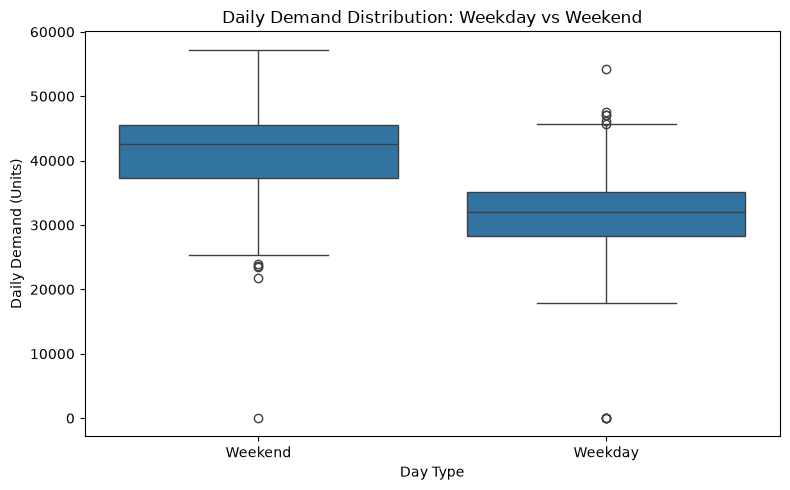

In [45]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=daily_demand,
    x="day_type",
    y="demand"
)

plt.title("Daily Demand Distribution: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Daily Demand (Units)")
plt.tight_layout()
plt.show()

##### Weekday vs Weekend — Key Observations

- Average demand was approximately **41,338 units on weekends**, compared with **31,533 units on weekdays**.
- Median demand was also higher on weekends (**42,527 units**) than on weekdays (**31,995 units**).
- Average weekend demand was approximately **31.1% higher** than weekday demand.
- The boxplot shows that the weekend demand distribution is consistently higher than the weekday distribution, rather than the difference being driven only by a few extreme observations.
- This recurring weekday–weekend pattern should be considered when developing the demand forecast.

#### 2.3.2.1 Weekly Seasonality

In [46]:
daily_demand = daily_demand.merge(
    calendar[["d", "year"]],
    on="d",
    how="left"
)

In [47]:
year_weekday_demand = (
    daily_demand
    .groupby(["year", "weekday"])["demand"]
    .mean()
    .reset_index()
)

year_weekday_demand

,year,weekday,demand
0,2011,Friday,26732.395833
1,2011,Monday,24923.291667
2,2011,Saturday,31949.020408
3,2011,Sunday,30608.000000
4,2011,Thursday,23301.104167
5,2011,Tuesday,23409.375000
6,2011,Wednesday,22923.395833
7,2012,Friday,33100.596154
8,2012,Monday,31652.150943
9,2012,Saturday,40162.750000


##### Weekly Seasonality — Key Observations

- The weekly demand pattern is consistent across the historical years.
- **Saturday and Sunday consistently record the highest average daily demand**, while Tuesday, Wednesday, and Thursday generally show lower demand.
- Although the overall demand level increases over time, the relative pattern across the days of the week remains similar.
- This recurring weekly pattern indicates the presence of **weekly seasonality** in historical demand.
- Weekly seasonality should therefore be considered when developing the demand forecast.

### 2.3.3 Within-month Demand Pattern

We now examine whether demand also varies according to the position of a day within the month.

The objective is to test whether demand tends to differ between the **start, middle, and end of the month**.

**Business Question:**

> Does demand show a recurring pattern based on where a day falls within the month?

#### Analysis Approach

We will group days into three periods:

- **Start of Month:** First 7 days
- **Middle of Month:** Days between the first and last 7 days
- **End of Month:** Last 7 days

This allows us to test whether demand systematically differs across these three periods.

In [48]:
days_in_month = daily_demand["date"].dt.days_in_month
day = daily_demand["date"].dt.day

daily_demand["month_period"] = np.select(
    [
        day <= 7,
        day > days_in_month - 7
    ],
    [
        "Start",
        "End"
    ],
    default="Middle"
)

In [49]:
daily_demand[
    ["date", "month_period", "demand"]
].head(15)

,date,month_period,demand
0,2011-01-29,End,32631
1,2011-01-30,End,31749
2,2011-01-31,End,23783
3,2011-02-01,Start,25412
4,2011-02-02,Start,19146
5,2011-02-03,Start,29211
6,2011-02-04,Start,28010
7,2011-02-05,Start,37932
8,2011-02-06,Start,32736
9,2011-02-07,Start,25572


In [50]:
month_period_demand = (
    daily_demand
    .groupby("month_period")["demand"]
    .agg(
        total_demand="sum",
        average_demand="mean",
        median_demand="median",
        demand_std="std"
    )
    .reset_index()
)

month_period_demand

,month_period,total_demand,average_demand,median_demand,demand_std
0,End,13857502,31638.132420,31429.5,7659.815715
1,Middle,35783698,34607.058027,33909.5,6992.094999
2,Start,16054209,36404.102041,35820.0,7052.264135


In [51]:
# Use Start of Month as the reference for comparing the other periods

start_avg = month_period_demand.loc[
    month_period_demand["month_period"] == "Start",
    "average_demand"
].iloc[0]

middle_avg = month_period_demand.loc[
    month_period_demand["month_period"] == "Middle",
    "average_demand"
].iloc[0]

end_avg = month_period_demand.loc[
    month_period_demand["month_period"] == "End",
    "average_demand"
].iloc[0]

middle_vs_start_pct = (
    (middle_avg - start_avg) / start_avg
) * 100

end_vs_start_pct = (
    (end_avg - start_avg) / start_avg
) * 100

print(f"Middle_vs_Start_pct: {middle_vs_start_pct}")
print(f"End_vs_Start_pct: {end_vs_start_pct}")

Middle_vs_Start_pct: -4.9363778063311905
End_vs_Start_pct: -13.091847768642632


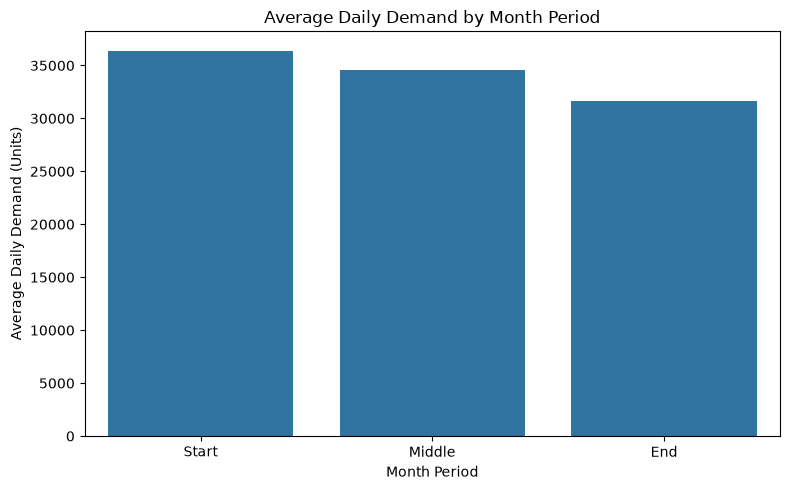

In [52]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=month_period_demand,
    x="month_period",
    y="average_demand",
    order=["Start", "Middle", "End"]
)

plt.title("Average Daily Demand by Month Period")
plt.xlabel("Month Period")
plt.ylabel("Average Daily Demand (Units)")
plt.tight_layout()
plt.show()

In [53]:
year_month_period = (
    daily_demand
    .assign(year=daily_demand["date"].dt.year)
    .groupby(["year", "month_period"])["demand"]
    .mean()
    .reset_index()
)

year_month_period

,year,month_period,demand
0,2011,End,23988.637500
1,2011,Middle,26602.000000
2,2011,Start,27910.831169
3,2012,End,30236.154762
4,2012,Middle,33135.489899
5,2012,Start,35252.059524
6,2013,End,33355.547619
7,2013,Middle,36115.213198
8,2013,Start,38323.690476
9,2014,End,32887.190476


##### Within-month Pattern — Key Observations

- Average daily demand is highest during the **Start of the Month**, followed by the Middle and End of the Month.
- The Start → Middle → End pattern is consistent across the historical years examined.
- Overall, average demand is approximately **4.9% lower in the Middle** and **13.1% lower at the End** compared with the Start of the month.
- This recurring within-month pattern may be useful as a time-based feature when developing the demand forecast.
- The pattern describes an association in the historical data; the analysis does not establish the underlying cause.

### 2.3.4 Month-of-Year Pattern

**Business Question:**

> Does demand show a recurring pattern across the months of the year?

We will analyze the monthly pattern from two perspectives:

1. Within-Year Month Comparison
2. Across-Year Month Comparison

This helps us determine whether demand for individual months is changing over time and whether the monthly pattern is consistent across years.

Together, these comparisons will help determine whether **month-of-year patterns are relevant for demand forecasting**.

In [54]:
daily_demand = daily_demand.merge(
    calendar[["d", "month"]],
    on="d",
    how="left"
)

In [55]:
daily_demand[["date", "year", "month", "demand"]].head()

,date,year,month,demand
0,2011-01-29,2011,1,32631
1,2011-01-30,2011,1,31749
2,2011-01-31,2011,1,23783
3,2011-02-01,2011,2,25412
4,2011-02-02,2011,2,19146


In [56]:
month_demand = (
    daily_demand
    .groupby(["year", "month"])["demand"]
    .mean()
    .reset_index()
)

month_demand

,year,month,demand
0,2011,1,29387.666667
1,2011,2,25941.964286
2,2011,3,24631.193548
3,2011,4,24590.433333
4,2011,5,23211.677419
...,...,...,...
59,2015,12,36330.193548
60,2016,1,39202.774194
61,2016,2,41825.068966
62,2016,3,41153.096774


In [57]:
month_demand_pivot = month_demand.pivot(
    index="month",
    columns="year",
    values="demand"
)

month_demand_pivot

year,2011,2012,2013,2014,2015,2016
month,,,,,,
1,29387.666667,28818.548387,32534.193548,34097.161290,34939.193548,39202.774194
2,25941.964286,30965.172414,36095.000000,36062.857143,36852.750000,41825.068966
3,24631.193548,31835.290323,36050.645161,36248.580645,36120.225806,41153.096774
4,24590.433333,31495.266667,34467.866667,36809.566667,36447.633333,43612.000000
5,23211.677419,32185.354839,34667.193548,35261.032258,37194.000000,NaN
6,25112.666667,36520.300000,37853.100000,37001.033333,38519.966667,NaN
7,26445.806452,34863.774194,37402.161290,37153.677419,39746.677419,NaN
8,26635.290323,35573.548387,38864.935484,38196.838710,40462.612903,NaN
9,27122.766667,35478.800000,38883.833333,36280.466667,39630.433333,NaN


#### 2.3.4.1 Within-Year Month Comparison

For each year, we will compare the months to identify:

- Which months have relatively higher demand
- Which months have relatively lower demand
- Whether similar high- and low-demand months appear repeatedly across years

In [58]:
yearly_month_extremes = []

for year in month_demand_pivot.columns:
    year_data = month_demand_pivot[year].dropna()

    highest_month = year_data.idxmax()
    lowest_month = year_data.idxmin()

    highest_demand = year_data.max()
    lowest_demand = year_data.min()

    yearly_month_extremes.append({
        "year": year,
        "highest_month": highest_month,
        "highest_demand": highest_demand,
        "lowest_month": lowest_month,
        "lowest_demand": lowest_demand
    })

yearly_month_extremes = pd.DataFrame(yearly_month_extremes)

yearly_month_extremes

,year,highest_month,highest_demand,lowest_month,lowest_demand
0,2011,1,29387.666667,5,23211.677419
1,2012,6,36520.300000,1,28818.548387
2,2013,9,38883.833333,1,32534.193548
3,2014,8,38196.838710,12,32692.000000
4,2015,8,40462.612903,1,34939.193548
5,2016,4,43612.000000,1,39202.774194


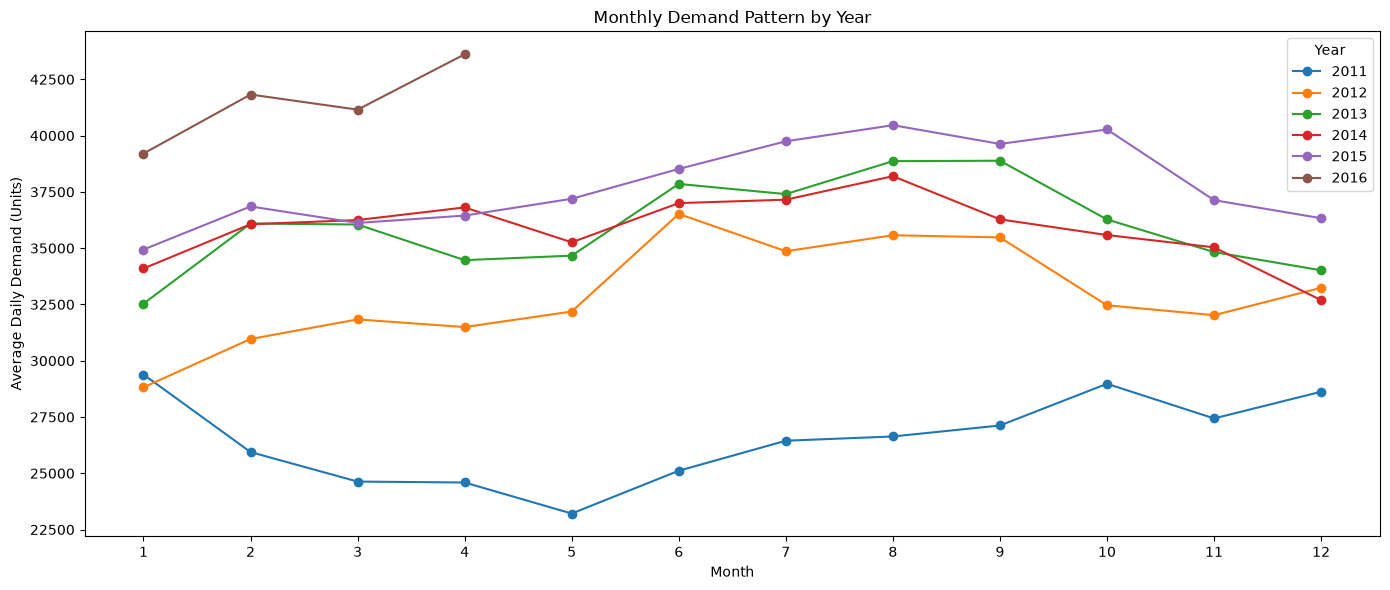

In [59]:
plt.figure(figsize=(14, 6))

for year in month_demand_pivot.columns:
    plt.plot(
        month_demand_pivot.index,
        month_demand_pivot[year],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Demand Pattern by Year")
plt.xlabel("Month")
plt.ylabel("Average Daily Demand (Units)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()

##### Within-Year Month Comparison — Key Observations

- The highest-demand month varies across years; there is no single month that consistently records the highest demand.
- In the complete years from **2012 to 2015**, demand generally increases toward the middle or later part of the year before declining toward the end of the year.
- This suggests that demand has a **recurring broad seasonal pattern**, although the exact peak month is not consistent every year.
- The 2011 and 2016 patterns should be interpreted cautiously because those years contain incomplete historical periods.

#### 2.3.4.2 Across-Year Month Comparison

**Business Question:**

> How does demand for the same month change over the years?

For each calendar month, we will compare demand across different years.

For example:
- January across 2011–2016
- February across 2011–2016
- March across 2011–2016
- and so on


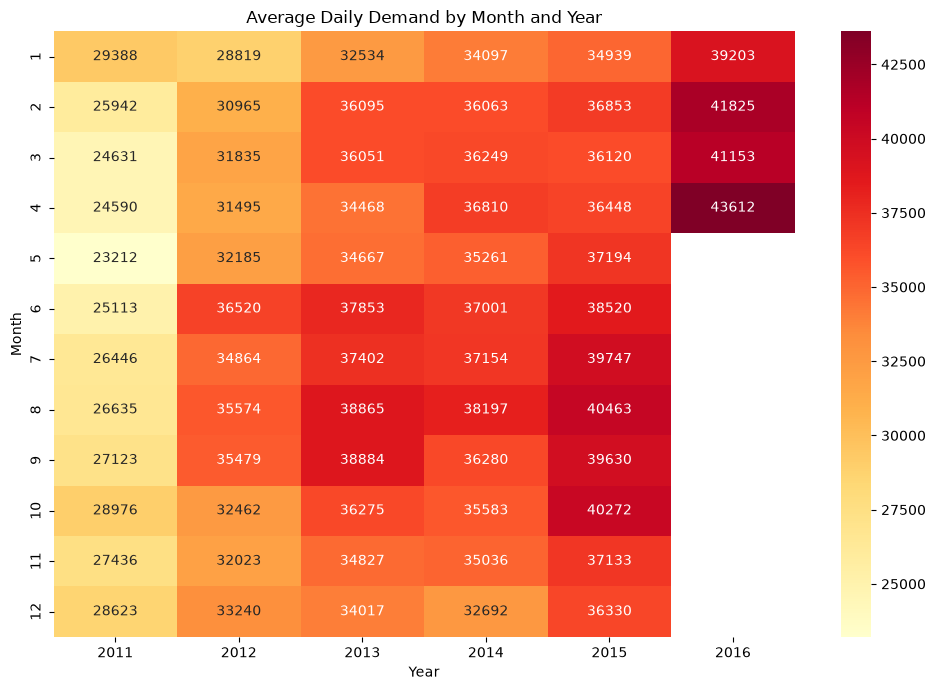

In [60]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    month_demand_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Average Daily Demand by Month and Year")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()
plt.show()

In [61]:
month_growth = pd.DataFrame({
    "month": month_demand_pivot.index,
    "2011_demand": month_demand_pivot[2011].values,
    "2015_demand": month_demand_pivot[2015].values
})

month_growth["growth_pct"] = (
    (month_growth["2015_demand"] - month_growth["2011_demand"])
    / month_growth["2011_demand"]
) * 100

month_growth

,month,2011_demand,2015_demand,growth_pct
0,1,29387.666667,34939.193548,18.890669
1,2,25941.964286,36852.750000,42.058441
2,3,24631.193548,36120.225806,46.644237
3,4,24590.433333,36447.633333,48.218752
4,5,23211.677419,37194.000000,60.238312
5,6,25112.666667,38519.966667,53.388595
6,7,26445.806452,39746.677419,50.294821
7,8,26635.290323,40462.612903,51.913542
8,9,27122.766667,39630.433333,46.115010
9,10,28975.580645,40272.161290,38.986555


##### Across-Year Month Comparison — Key Observations

- Average daily demand increased from **2011 to 2015 for every month**.
- The increase ranged from approximately **18.9% in January** to **60.2% in May**.
- **May showed the largest increase**, followed by June, August, and July.
- **January showed the smallest increase**, followed by December.
- Demand growth therefore occurred across the calendar year, but the rate of growth differed by month.
- The results show that **long-term demand growth and month-of-year variation are both relevant demand patterns to consider when developing the forecast**.
- However, the monthly pattern is not identical across years, so its contribution to forecast accuracy should be evaluated rather than assumed.

### 2.3.5 Recurring Demand Peaks

We now examine whether unusually high-demand periods occur repeatedly across different years.

**Business Question:**

> Do major demand peaks occur repeatedly at similar times of the year?

In [62]:
daily_demand["month_day"] = daily_demand["date"].dt.strftime("%m-%d")

recurring_peaks = (
    daily_demand
    .groupby("month_day")["demand"]
    .agg(
        average_demand="mean",
        max_demand="max",
        occurrences="count"
    )
    .reset_index()
    .sort_values("average_demand", ascending=False)
)

recurring_peaks.head(10)

,month_day,average_demand,max_demand,occurrences
184,07-03,42779.200000,54154,5
215,08-03,41336.400000,47572,5
166,06-15,40687.800000,47580,5
214,08-02,40190.000000,51541,5
278,10-05,40022.600000,48777,5
221,08-09,39827.800000,51961,5
93,04-03,39803.666667,56425,6
250,09-07,39707.000000,47600,5
276,10-03,39682.600000,54687,5
285,10-12,39604.400000,46735,5


In [63]:
peak_dates_by_year = (
    daily_demand[
        daily_demand["month_day"].isin(
            recurring_peaks.head(10)["month_day"]
        )
    ][["date", "year", "month_day", "demand"]]
    .sort_values(["month_day", "year"])
)

peak_dates_by_year

,date,year,month_day,demand
64,2011-04-03,2011,04-03,33058
430,2012-04-03,2012,04-03,33033
795,2013-04-03,2013,04-03,35594
1160,2014-04-03,2014,04-03,36604
1525,2015-04-03,2015,04-03,44108
1891,2016-04-03,2016,04-03,56425
137,2011-06-15,2011,06-15,25258
503,2012-06-15,2012,06-15,41798
868,2013-06-15,2013,06-15,46309
1233,2014-06-15,2014,06-15,42494


##### Recurring Demand Peaks — Key Observations

- Several calendar dates show relatively high demand repeatedly across multiple years.
- **July 3** is a clear example, with demand increasing from **29,173 units in 2011** to **54,154 units in 2015**.
- **August 2, August 9, and October 3** also show relatively high demand across each year examined.
- These dates show that some high-demand periods recur at similar points in the calendar.
- The demand levels generally increase over the years, so the recurring peaks should be considered together with the overall upward demand trend when developing the forecast.

### 2.3.6 Recurring Demand Drops

We now examine whether unusually low-demand periods occur repeatedly at similar times of the year.

**Business Question:**

> Do major demand drops occur repeatedly at similar times of the year?

In [64]:
recurring_drops = (
    daily_demand
    .groupby("month_day")["demand"]
    .agg(
        average_demand="mean",
        min_demand="min",
        occurrences="count"
    )
    .reset_index()
    .sort_values("average_demand")
)

recurring_drops.head(10)

,month_day,average_demand,min_demand,occurrences
359,12-25,15.6,11,5
332,11-28,25265.6,19839,5
0,01-01,25768.4,21807,5
331,11-27,27437.4,21844,5
149,05-29,27930.0,23449,5
120,04-30,28607.4,27356,5
330,11-26,28719.0,23631,5
333,11-29,28752.6,21584,5
119,04-29,28967.2,22735,5
141,05-21,29177.4,27112,5


In [65]:
dec_25 = (
    daily_demand[
        daily_demand["month_day"] == "12-25"
    ][["date", "year", "demand"]]
    .sort_values("year")
)

dec_25

,date,year,demand
330,2011-12-25,2011,13
696,2012-12-25,2012,11
1061,2013-12-25,2013,20
1426,2014-12-25,2014,20
1791,2015-12-25,2015,14


##### Recurring Demand Drops — Key Observations

- **December 25 shows an exceptionally low demand level in every year from 2011 to 2015**, ranging from only 11 to 20 units.
- The repeated drop on the same calendar date indicates a strong **annual recurring pattern** in the historical data.
- This recurring demand drop should be considered when developing the forecast because a forecast based only on the general trend could substantially overestimate demand for this period.

## 3. Demand by Business Dimension

### 3.1 Product Hierarchy Demand

Demand is organized into a product hierarchy:

Category → Department → Product

We will analyze demand at each level to understand how total demand is distributed across the hierarchy.

**Business Question:**

> How is demand distributed across the product hierarchy?

#### 3.1.1 Category Demand

We begin at the highest level of the product hierarchy by examining demand across categories.

The dataset contains three product categories:
- **FOODS**
- **HOUSEHOLD**
- **HOBBIES**

We will compare:
- Total demand
- Demand contribution
- Average daily demand
- Relative demand variability

**Business Question:**

> How is demand distributed across the major product categories?

In [66]:
category_daily_demand = (
    sales_historical
    .groupby(["d", "cat_id"])["demand"]
    .sum()
    .reset_index()
)

> 1 row = 1 category × 1 day

In [67]:
# Calculate Category level Metrics

category_demand = (
    category_daily_demand
    .groupby("cat_id")["demand"]
    .agg(
        total_demand="sum",
        average_daily_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

In [68]:
# Calculate Contribution %

total_demand = category_demand["total_demand"].sum()

category_demand["contribution_pct"] = (
    category_demand["total_demand"] / total_demand
) * 100

In [69]:
# Calculate relative variability

category_demand["cv"] = (
    category_demand["demand_std"]
    / category_demand["average_daily_demand"]
) * 100

category_demand

,cat_id,total_demand,average_daily_demand,demand_std,contribution_pct,cv
0,FOODS,45089939,23570.276529,4908.505905,68.634840,20.824982
1,HOBBIES,6124800,3201.672765,706.371092,9.323026,22.062564
2,HOUSEHOLD,14480670,7569.613173,2194.630349,22.042134,28.992635


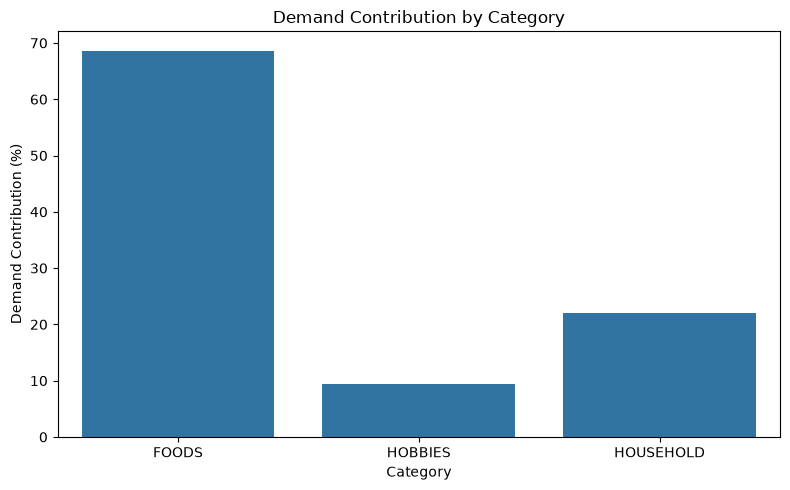

In [70]:
# Category Demand contribution chart

plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_demand,
    x="cat_id",
    y="contribution_pct"
)

plt.title("Demand Contribution by Category")
plt.xlabel("Category")
plt.ylabel("Demand Contribution (%)")
plt.tight_layout()
plt.show()

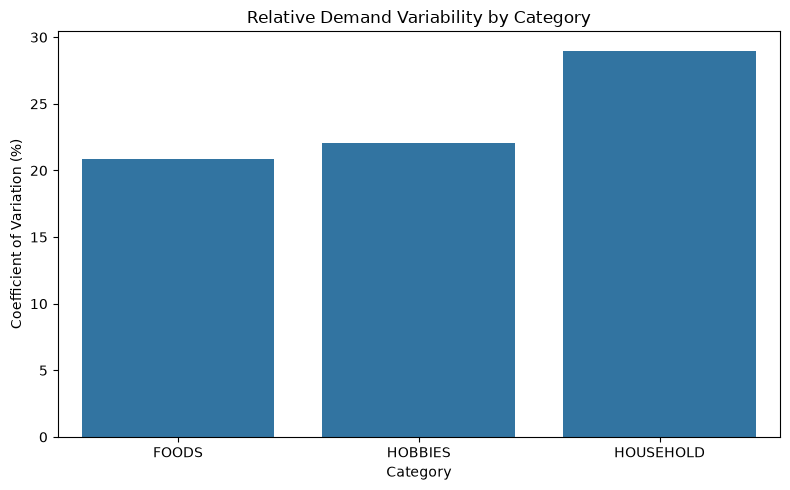

In [71]:
# Category Relative variability chart

plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_demand,
    x="cat_id",
    y="cv"
)

plt.title("Relative Demand Variability by Category")
plt.xlabel("Category")
plt.ylabel("Coefficient of Variation (%)")
plt.tight_layout()
plt.show()

##### Category Demand — Key Observations

- **FOODS contributes the majority of historical demand**, accounting for approximately **68.6%** of total units sold.
- **HOUSEHOLD contributes 22.0%**, while **HOBBIES contributes 9.3%**.
- FOODS also has the highest average daily demand at approximately **23,570 units**.
- **HOUSEHOLD has the highest relative demand variability**, with a coefficient of variation of approximately **29.0%**, compared with 20.8% for FOODS and 22.1% for HOBBIES.
- The results show that demand is concentrated in FOODS, while the categories differ in their relative demand variability. These differences may be relevant when evaluating forecast performance across categories.

#### 3.1.2 Department Demand

We now move one level down the product hierarchy and examine demand across departments.

Departments provide more detail than categories and help identify where demand is concentrated within each major product category.

We will compare:
- Total demand
- Demand contribution

**Business Question:**

> How is demand distributed across departments within the product hierarchy?

In [72]:
# Calculate total demand by department

department_demand = (
    sales_historical
    .groupby("dept_id")["demand"]
    .sum()
    .reset_index(name="total_demand")
)

> one row per department

In [73]:
department_demand

,dept_id,total_demand
0,FOODS_1,5088041
1,FOODS_2,7629822
2,FOODS_3,32372076
3,HOBBIES_1,5596460
4,HOBBIES_2,528340
5,HOUSEHOLD_1,11500526
6,HOUSEHOLD_2,2980144


In [74]:
# Calculate demand contribution %

total_demand = department_demand["total_demand"].sum()

department_demand["contribution_pct"] = (
    department_demand["total_demand"] / total_demand
) * 100

department_demand = department_demand.sort_values(
    "total_demand",
    ascending=False
)

department_demand

,dept_id,total_demand,contribution_pct
2,FOODS_3,32372076,49.276010
5,HOUSEHOLD_1,11500526,17.505829
1,FOODS_2,7629822,11.613935
3,HOBBIES_1,5596460,8.518799
0,FOODS_1,5088041,7.744896
6,HOUSEHOLD_2,2980144,4.536305
4,HOBBIES_2,528340,0.804227


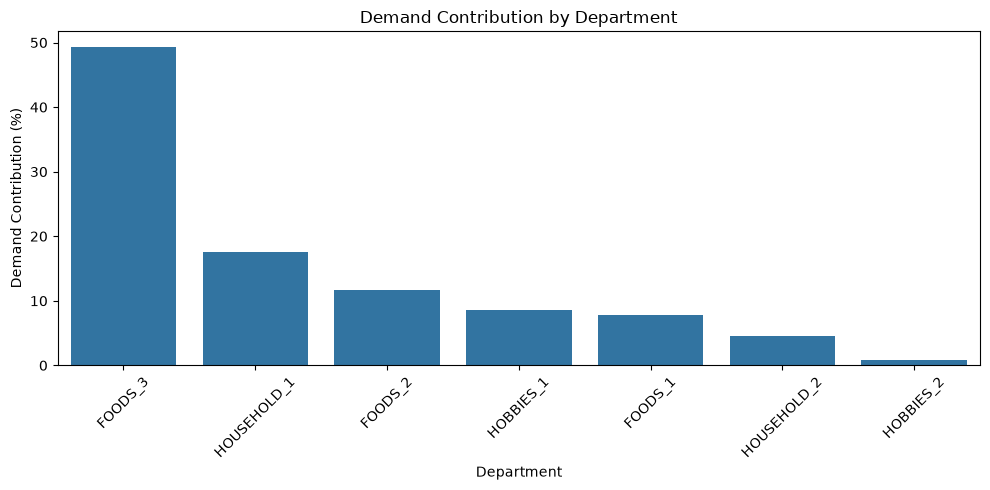

In [75]:
# Department contribution chart

plt.figure(figsize=(10, 5))

sns.barplot(
    data=department_demand,
    x="dept_id",
    y="contribution_pct"
)

plt.title("Demand Contribution by Department")
plt.xlabel("Department")
plt.ylabel("Demand Contribution (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Department Demand — Key Observations

- **FOODS_3 contributes approximately 49.3% of total historical demand**, making it the largest-demand department by a substantial margin.
- **HOUSEHOLD_1 contributes 17.5%**, followed by **FOODS_2 at 11.6%**.
- The remaining departments each contribute less than 10% of total demand.
- Within the FOODS category, demand is concentrated mainly in **FOODS_3 and FOODS_2**, while HOBBIES and HOUSEHOLD demand are distributed across their respective departments.
- The department-level results show that overall retail demand is not evenly distributed across the product hierarchy.

#### 3.1.3 Product Demand

We now move to the lowest level of the product hierarchy and examine demand across individual products.

We will examine:

- Total demand by product
- Average daily demand by product
- Top- and lowest-demand products
- Product demand distribution
- Demand concentration

**Business Question:**

> Which products drive demand, and how concentrated is demand across products?

In [76]:
product_daily_demand = (
    sales_historical
    .groupby(["d", "item_id"])["demand"]
    .sum()
    .reset_index()
)

product_daily_demand

,d,item_id,demand
0,d_1,FOODS_1_001,6
1,d_1,FOODS_1_002,4
2,d_1,FOODS_1_003,14
3,d_1,FOODS_1_004,0
4,d_1,FOODS_1_005,34
...,...,...,...
5832732,d_999,HOUSEHOLD_2_512,4
5832733,d_999,HOUSEHOLD_2_513,6
5832734,d_999,HOUSEHOLD_2_514,1
5832735,d_999,HOUSEHOLD_2_515,0


> 1 row = 1 product × 1 day

In [77]:
product_demand = (
    product_daily_demand
    .groupby("item_id")["demand"]
    .agg(
        total_demand="sum",
        average_daily_demand="mean",
        median_daily_demand="median",
        demand_std="std"
    )
    .reset_index()
)

product_demand

,item_id,total_demand,average_daily_demand,median_daily_demand,demand_std
0,FOODS_1_001,12247,6.401986,6.0,4.988054
1,FOODS_1_002,7334,3.833769,4.0,2.329448
2,FOODS_1_003,13394,7.001568,6.0,4.023401
3,FOODS_1_004,129481,67.684788,70.0,55.959166
4,FOODS_1_005,22914,11.978045,11.0,10.479235
...,...,...,...,...,...
3044,HOUSEHOLD_2_512,11555,6.040251,5.0,3.616118
3045,HOUSEHOLD_2_513,7916,4.138003,3.0,4.810291
3046,HOUSEHOLD_2_514,3150,1.646628,1.0,1.628897
3047,HOUSEHOLD_2_515,1121,0.585991,0.0,1.106302


> 1 row = 1 product

In [78]:
# Check the product demand distribution

product_demand["total_demand"].describe()

count    3.049000e+03
mean     2.154654e+04
std      4.425243e+04
min      5.680000e+02
25%      4.310000e+03
50%      9.526000e+03
75%      2.140600e+04
max      1.002529e+06
Name: total_demand, dtype: float64

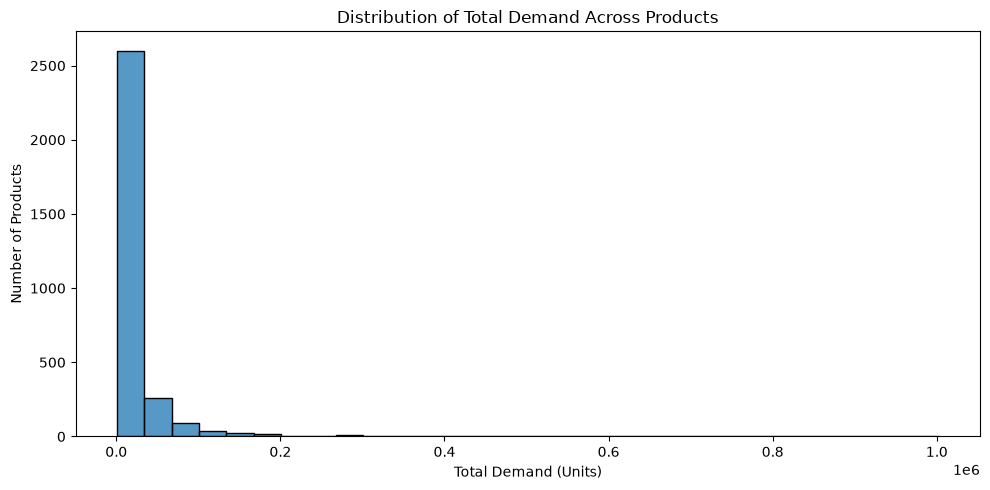

In [79]:
# Visualize the product demand distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    product_demand["total_demand"],
    bins=30
)

plt.title("Distribution of Total Demand Across Products")
plt.xlabel("Total Demand (Units)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

In [80]:
# Demand Concentration

product_demand["demand_band"] = pd.qcut(
    product_demand["total_demand"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

In [81]:
# Calculate demand contribution by demand band

demand_band_summary = (
    product_demand
    .groupby("demand_band", observed=True)["total_demand"]
    .agg(
        product_count="count",
        total_demand="sum"
    )
    .reset_index()
)

demand_band_summary["demand_contribution_pct"] = (
    demand_band_summary["total_demand"]
    / product_demand["total_demand"].sum()
) * 100

demand_band_summary

,demand_band,product_count,total_demand,demand_contribution_pct
0,Low,763,1949853,2.968020
1,Medium-Low,762,5151375,7.841301
2,Medium-High,762,11065503,16.843647
3,High,762,47528678,72.347031


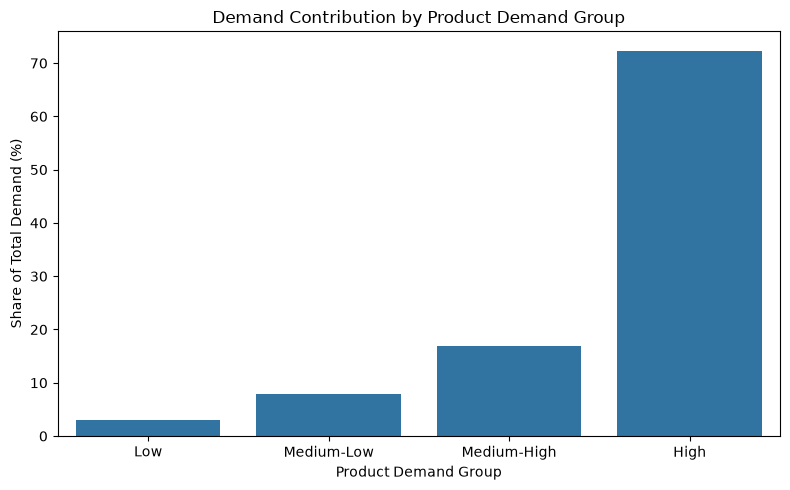

In [82]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=demand_band_summary,
    x="demand_band",
    y="demand_contribution_pct"
)

plt.title("Demand Contribution by Product Demand Group")
plt.xlabel("Product Demand Group")
plt.ylabel("Share of Total Demand (%)")
plt.tight_layout()
plt.show()

##### Product Demand — Key Observations

- Product demand varies substantially across the **3,049 products**, with most products having relatively low total demand and a smaller group having much higher demand.
- The average total demand per product (**21,547 units**) is considerably higher than the median (**9,526 units**), indicating that high-demand products raise the overall average.
- The highest-demand 25% of products account for approximately **72.3% of total historical demand**, while the lowest 25% account for only **3.0%**.
- This shows that demand is strongly concentrated toward the higher-demand group of products rather than being evenly distributed across the product range.
- This concentration is relevant for forecasting because forecast performance may differ between high-demand and lower-demand products.

### 3.2 Store & State Demand

Demand can vary across geographic locations. We first examine demand at the state level and then move to individual stores.

#### 3.2.1 State Demand 

The dataset contains 3 states:
- California (CA)
- Texas (TX)
- Wisconsin (WI)

**Business Question:**

> How does demand differ across locations?

In [83]:
state_daily_demand = (
    sales_historical
    .groupby(["d", "state_id"])["demand"]
    .sum()
    .reset_index()
)

state_daily_demand.head()

,d,state_id,demand
0,d_1,CA,14195
1,d_1,TX,9438
2,d_1,WI,8998
3,d_10,CA,11822
4,d_10,TX,7319


> 1 row = 1 state × 1 day

In [84]:
# Calculate state-level demand metrics

state_demand = (
    state_daily_demand
    .groupby("state_id")["demand"]
    .agg(
        total_demand="sum",
        average_daily_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

total_demand = state_demand["total_demand"].sum()

state_demand["contribution_pct"] = (
    state_demand["total_demand"] / total_demand
) * 100

state_demand["cv"] = (
    state_demand["demand_std"]
    / state_demand["average_daily_demand"]
) * 100

state_demand = state_demand.sort_values(
    "total_demand",
    ascending=False
)

state_demand

,state_id,total_demand,average_daily_demand,demand_std,contribution_pct,cv
0,CA,28675547,14989.831155,3257.223505,43.649240,21.729554
1,TX,18899006,9879.250392,1964.928938,28.767621,19.889454
2,WI,18120856,9472.480920,2563.314535,27.583139,27.060646


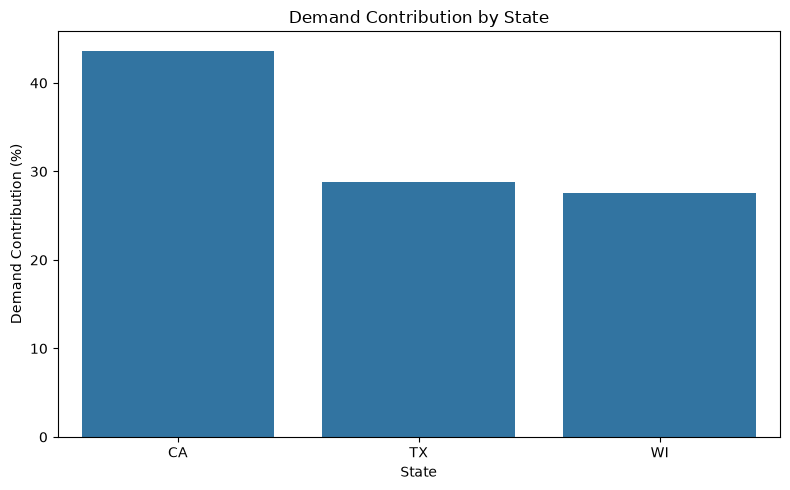

In [85]:
# Visualize state demand

plt.figure(figsize=(8, 5))

sns.barplot(
    data=state_demand,
    x="state_id",
    y="contribution_pct"
)

plt.title("Demand Contribution by State")
plt.xlabel("State")
plt.ylabel("Demand Contribution (%)")
plt.tight_layout()
plt.show()

##### State Demand — Key Observations

- **CA contributes the largest share of historical demand at 43.6%**, followed by TX at 28.8% and WI at 27.6%.
- CA also has the highest average daily demand at approximately **14,990 units**.
- **WI has the highest relative demand variability**, with a CV of approximately **27.1%**.
- Therefore, demand differs across states in both **demand level and variability**, which may be relevant when evaluating forecast performance by location.

#### 3.2.2 Store Demand

We now move from the state level to individual stores to examine how demand is distributed across locations.

We will compare:

- Total demand
- Average daily demand
- Demand variability

**Business Question:**

> How does demand differ across individual stores?

In [86]:
store_daily_demand = (
    sales_historical
    .groupby(["d", "store_id"])["demand"]
    .sum()
    .reset_index()
)

store_daily_demand.head(10)

,d,store_id,demand
0,d_1,CA_1,4337
1,d_1,CA_2,3494
2,d_1,CA_3,4739
3,d_1,CA_4,1625
4,d_1,TX_1,2556
5,d_1,TX_2,3852
6,d_1,TX_3,3030
7,d_1,WI_1,2704
8,d_1,WI_2,2256
9,d_1,WI_3,4038


> 1 row = 1 store × 1 day

In [87]:
# Calculate store-level demand metrics

store_demand = (
    store_daily_demand
    .groupby("store_id")["demand"]
    .agg(
        total_demand="sum",
        average_daily_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

total_demand = store_demand["total_demand"].sum()

store_demand["contribution_pct"] = (
    store_demand["total_demand"] / total_demand
) * 100

store_demand["cv"] = (
    store_demand["demand_std"]
    / store_demand["average_daily_demand"]
) * 100

store_demand = store_demand.sort_values(
    "total_demand",
    ascending=False
)

store_demand

,store_id,total_demand,average_daily_demand,demand_std,contribution_pct,cv
2,CA_3,11188180,5848.499739,1200.731543,17.030383,20.530591
0,CA_1,7698216,4024.158913,991.847206,11.718043,24.647317
5,TX_2,7214384,3771.240983,792.894722,10.981565,21.024769
8,WI_2,6544012,3420.811291,1284.960834,9.961141,37.563044
9,WI_3,6427782,3360.053319,825.531851,9.784218,24.569010
6,TX_3,6089330,3183.131208,681.376424,9.269034,21.405854
1,CA_2,5685475,2972.020387,900.059626,8.654296,30.284436
4,TX_1,5595292,2924.878202,614.763981,8.517021,21.018447
7,WI_1,5149062,2691.616309,997.253859,7.837781,37.050372
3,CA_4,4103676,2145.152117,427.928177,6.246519,19.948617


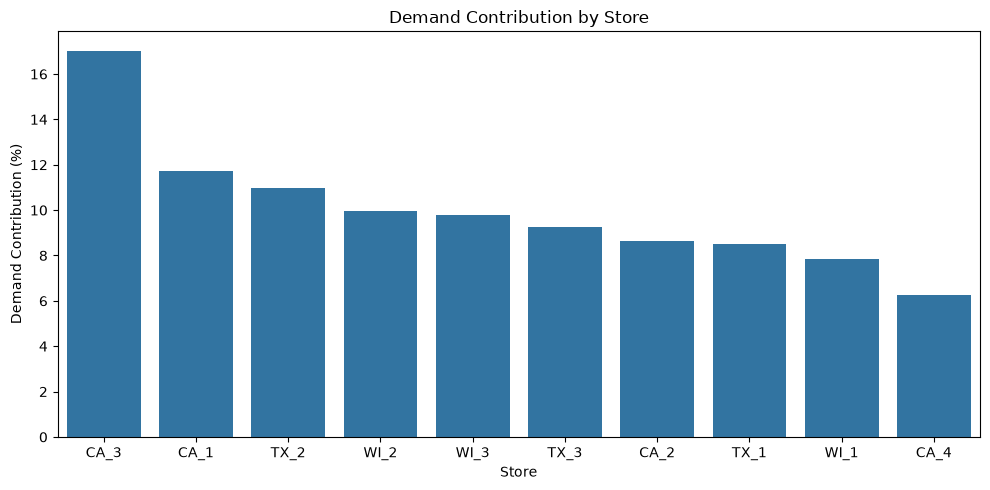

In [88]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=store_demand,
    x="store_id",
    y="contribution_pct"
)

plt.title("Demand Contribution by Store")
plt.xlabel("Store")
plt.ylabel("Demand Contribution (%)")
plt.tight_layout()
plt.show()

##### Store Demand — Key Observations

- Demand is not evenly distributed across stores.
- **CA_3 is the highest-demand store**, contributing approximately **17.0%** of total historical demand.
- The next largest contributors are **CA_1 (11.7%)** and **TX_2 (11.0%)**.
- The lowest-demand store is **CA_4**, contributing approximately **6.2%** of total demand.
- Store demand variability also differs substantially.
- **WI_2 (CV = 37.6%)** and **WI_1 (CV = 37.1%)** show the highest relative demand variability.
- **CA_4 (CV = 19.9%)** shows the lowest relative variability.
- These results indicate that stores differ not only in demand volume but also in demand stability, which may influence forecast accuracy and inventory planning.

#### 3.2.3 Store × Category Demand

We now examine demand across stores and product categories together.

The objective is to determine whether different stores have different category demand patterns.

**Business Question:**

> Do different stores show different category demand patterns?

In [89]:
store_category_demand = (
    sales_historical
    .groupby(["store_id", "cat_id"])["demand"]
    .sum()
    .reset_index()
)

store_category_demand

,store_id,cat_id,demand
0,CA_1,FOODS,5380828
1,CA_1,HOBBIES,876678
2,CA_1,HOUSEHOLD,1440710
3,CA_2,FOODS,3480259
4,CA_2,HOBBIES,637803
5,CA_2,HOUSEHOLD,1567413
6,CA_3,FOODS,7515790
7,CA_3,HOBBIES,960947
8,CA_3,HOUSEHOLD,2711443
9,CA_4,FOODS,2819425


> 1 row = 1 store × 1 category

In [90]:
store_category_mix = store_category_demand.copy()

store_totals = (
    store_category_mix
    .groupby("store_id")["demand"]
    .transform("sum")
)

store_category_mix["demand_share_pct"] = (
    store_category_mix["demand"] / store_totals
) * 100

store_category_mix

,store_id,cat_id,demand,demand_share_pct
0,CA_1,FOODS,5380828,69.897077
1,CA_1,HOBBIES,876678,11.388067
2,CA_1,HOUSEHOLD,1440710,18.714855
3,CA_2,FOODS,3480259,61.213162
4,CA_2,HOBBIES,637803,11.218113
5,CA_2,HOUSEHOLD,1567413,27.568726
6,CA_3,FOODS,7515790,67.176163
7,CA_3,HOBBIES,960947,8.588948
8,CA_3,HOUSEHOLD,2711443,24.234889
9,CA_4,FOODS,2819425,68.704864


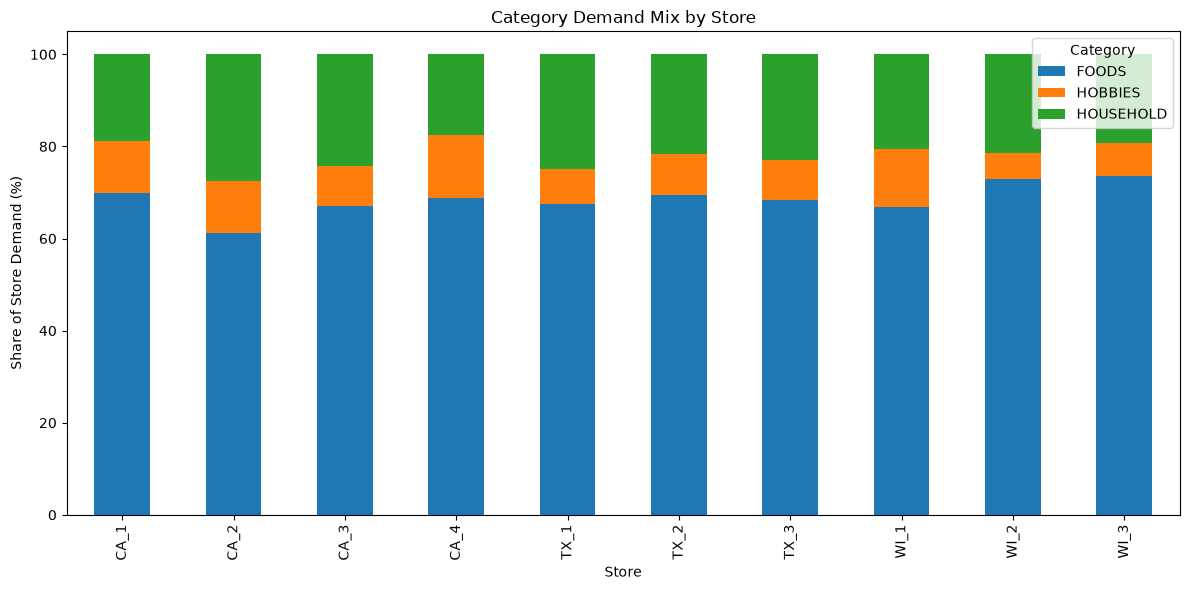

In [91]:
store_category_pivot = (
    store_category_mix
    .pivot(
        index="store_id",
        columns="cat_id",
        values="demand_share_pct"
    )
)

store_category_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Category Demand Mix by Store")
plt.xlabel("Store")
plt.ylabel("Share of Store Demand (%)")
plt.legend(title="Category")
plt.tight_layout()
plt.show()

##### Store × Category — Key Observations

- FOODS is the largest demand category across every store, accounting for approximately **61%–74%** of store demand.
- HOUSEHOLD shows more variation across stores, contributing approximately **18%–28%** of store demand.
- HOBBIES remains the smallest category across all stores, contributing approximately **6%–14%**.
- Overall, stores have a similar category structure, but the relative demand mix differs across locations.
- This indicates that location-level forecasting may benefit from considering category mix rather than treating all stores as having identical demand patterns.

## 4. Demand Drivers

> **Note:** Driver analysis identifies associations between demand and potential drivers. It does not establish causation.

### 4.1 Event Analysis

We now examine whether demand differs between event periods and normal periods.

The objective is to determine whether event periods are associated with noticeable changes in demand.

We will compare:
- Event vs non-event demand
- Demand distribution and variability
- Demand around selected event dates
- Demand across event types

**Business Question:**

> Are event periods associated with noticeable demand changes?

#### 4.1.1 Event vs Non-Event 

In [92]:
# create the event indicator

calendar["is_event"] = (
    calendar["event_name_1"].notna()
    | calendar["event_name_2"].notna()
)

In [93]:
calendar["is_event"].value_counts()

is_event
False    1807
True      162
Name: count, dtype: int64

In [94]:
calendar[["event_type_1", "event_type_2"]].stack().value_counts()

Religious    56
National     52
Cultural     41
Sporting     18
Name: count, dtype: int64

In [95]:
# Create the event vs non-event demand dataset

daily_demand = daily_demand.merge(
    calendar[["d", "is_event"]],
    on="d",
    how="left"
)

daily_demand[["d", "demand", "is_event"]].head()

,d,demand,is_event
0,d_1,32631,False
1,d_2,31749,False
2,d_3,23783,False
3,d_4,25412,False
4,d_5,19146,False


> 1 row = 1 day + total daily demand + event status

In [96]:
event_demand = (
    daily_demand
    .groupby("is_event")["demand"]
    .agg(
        average_demand="mean",
        median_demand="median",
        demand_std="std"
    )
    .reset_index()
)

event_demand

,is_event,average_demand,median_demand,demand_std
0,False,34489.207504,33714.0,7133.701801
1,True,32655.149351,33779.5,9300.905832


In [97]:
# calculate the demand difference

event_avg = event_demand.loc[
    event_demand["is_event"] == True,
    "average_demand"
].iloc[0]

non_event_avg = event_demand.loc[
    event_demand["is_event"] == False,
    "average_demand"
].iloc[0]

demand_change_pct = (
    (event_avg - non_event_avg)
    / non_event_avg
) * 100

demand_change_pct

np.float64(-5.317774128001345)

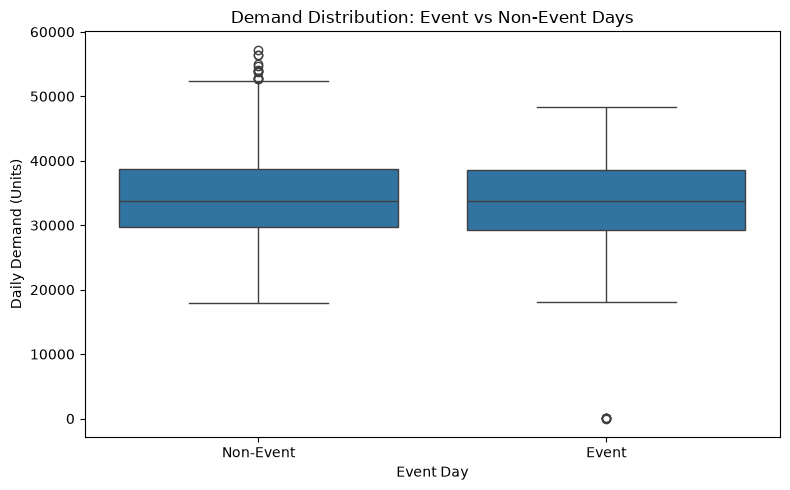

In [98]:
# Compare the demand distributions

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=daily_demand,
    x="is_event",
    y="demand"
)

plt.title("Demand Distribution: Event vs Non-Event Days")
plt.xlabel("Event Day")
plt.ylabel("Daily Demand (Units)")
plt.xticks(
    [0, 1],
    ["Non-Event", "Event"]
)

plt.tight_layout()
plt.show()

##### Event vs Non-Event Demand — Key Observations

- Average daily demand was approximately **34,489 units on non-event days** and **32,655 units on event days**, a difference of about **5.3%**.
- Median demand was very similar between the two groups, at **33,714 units for non-event days** and **33,780 units for event days**.
- Event days showed higher demand variability, with a standard deviation of approximately **9,301 units**, compared with **7,134 units** on non-event days.
- The demand distributions were broadly similar, although event days showed some unusual observations and greater variability.
- Overall, event days do not show a consistent shift in typical demand levels, but they are associated with greater variation in daily demand.

#### Event vs Non-Event Day-to-Day Change


In [99]:
event_change = (
    daily_demand
    .groupby("is_event")["demand_change"]
    .agg(
        average_change="mean",
        median_change="median",
        change_std="std",
        minimum_change="min",
        maximum_change="max"
    )
    .reset_index()
)

event_change

,is_event,average_change,median_change,change_std,minimum_change,maximum_change
0,False,387.149602,246.0,5624.62975,-16656.0,38363.0
1,True,-4308.084416,-2780.5,7426.31239,-36213.0,8419.0


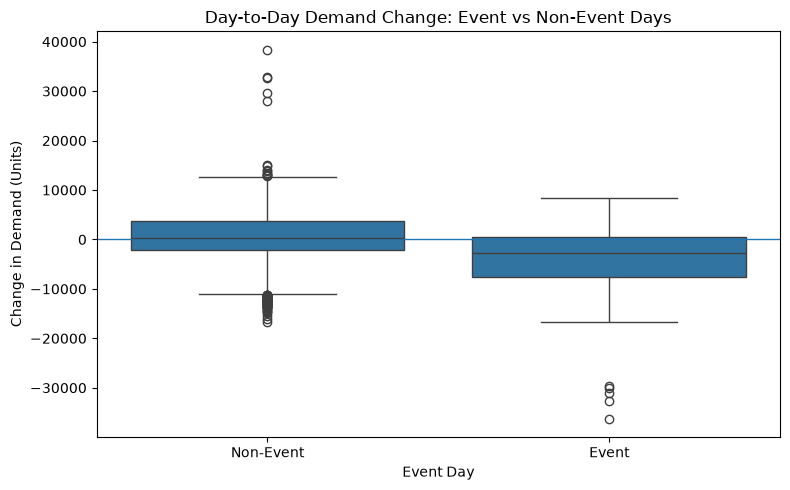

In [100]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=daily_demand,
    x="is_event",
    y="demand_change"
)

plt.title("Day-to-Day Demand Change: Event vs Non-Event Days")
plt.xlabel("Event Day")
plt.ylabel("Change in Demand (Units)")
plt.xticks(
    [0, 1],
    ["Non-Event", "Event"]
)

plt.axhline(0, linewidth=1)

plt.tight_layout()
plt.show()

##### Event vs Non-Event Day-to-Day Change — Key Observations

- Event days show a more negative typical day-to-day demand change than non-event days.
- The median change was approximately **-2,781 units on event days**, compared with **+246 units on non-event days**.
- Event days also show greater variability in demand changes.
- The distribution indicates that some event days are associated with particularly large demand drops.
- This suggests that event periods may coincide with sharper demand movements, which could be relevant when evaluating forecast errors.

#### 4.1.2 Demand Around Specific Event Dates

We now examine demand around specific event dates to understand whether noticeable demand changes occur immediately before, during, or after an event.

The analysis will use a short time window around selected event dates.

**Business Question:**

> Do specific event periods coincide with noticeable changes in demand around the event date?

In [101]:
# Identify event dates with large demand movements
# Find the largest event-day decreases

event_dates = (
    daily_demand[daily_demand["is_event"]]
    [["d", "date", "demand", "demand_change"]]
    .sort_values("demand_change")
)

event_dates.head(10)

,d,date,demand,demand_change
1791,d_1792,2015-12-25,14,-36213.0
696,d_697,2012-12-25,11,-32612.0
1061,d_1062,2013-12-25,20,-31057.0
330,d_331,2011-12-25,13,-29945.0
1426,d_1427,2014-12-25,20,-29597.0
1617,d_1618,2015-07-04,37489,-16665.0
1762,d_1763,2015-11-26,23631,-16493.0
1034,d_1035,2013-11-28,19839,-16300.0
1599,d_1600,2015-06-16,31698,-15882.0
1398,d_1399,2014-11-27,21844,-15059.0


In [102]:
# Find the largest event-day increases

event_dates_increases = (
    daily_demand[daily_demand["is_event"]]
    [["d", "date", "demand", "demand_change"]]
    .sort_values("demand_change", ascending=False)
)

event_dates_increases.head(10)

,d,date,demand,demand_change
1533,d_1534,2015-04-11,45272,8419.0
636,d_637,2012-10-26,31863,7551.0
413,d_414,2012-03-17,37904,6953.0
343,d_344,2012-01-07,37143,6738.0
441,d_442,2012-04-14,38546,6608.0
462,d_463,2012-05-05,39201,6269.0
1344,d_1345,2014-10-04,47199,5363.0
1477,d_1478,2015-02-14,41614,4678.0
538,d_539,2012-07-20,35402,4538.0
1311,d_1312,2014-09-01,43256,4046.0


In [103]:
top_event_dates = pd.concat([
    event_dates.head(10),
    event_dates_increases.head(10)
]).drop_duplicates("date")

top_event_dates = top_event_dates.merge(
    calendar[
        [
            "date",
            "event_name_1",
            "event_type_1",
            "event_name_2",
            "event_type_2"
        ]
    ],
    on="date",
    how="left"
)

top_event_dates.sort_values(
    "demand_change"
)

,d,date,demand,demand_change,event_name_1,event_type_1,event_name_2,event_type_2
0,d_1792,2015-12-25,14,-36213.0,Christmas,National,NaN,NaN
1,d_697,2012-12-25,11,-32612.0,Christmas,National,NaN,NaN
2,d_1062,2013-12-25,20,-31057.0,Christmas,National,NaN,NaN
3,d_331,2011-12-25,13,-29945.0,Christmas,National,NaN,NaN
4,d_1427,2014-12-25,20,-29597.0,Christmas,National,NaN,NaN
5,d_1618,2015-07-04,37489,-16665.0,IndependenceDay,National,NaN,NaN
6,d_1763,2015-11-26,23631,-16493.0,Thanksgiving,National,NaN,NaN
7,d_1035,2013-11-28,19839,-16300.0,Thanksgiving,National,NaN,NaN
8,d_1600,2015-06-16,31698,-15882.0,NBAFinalsEnd,Sporting,NaN,NaN
9,d_1399,2014-11-27,21844,-15059.0,Thanksgiving,National,NaN,NaN


In [104]:
event_counts = pd.concat([
    calendar["event_name_1"],
    calendar["event_name_2"]
]).dropna().value_counts()

event_counts

SuperBowl              6
ValentinesDay          6
PresidentsDay          6
LentStart              6
LentWeek2              6
StPatricksDay          6
Purim End              6
OrthodoxEaster         6
Pesach End             6
Cinco De Mayo          6
Mother's day           6
MemorialDay            6
NBAFinalsStart         6
NBAFinalsEnd           6
Father's day           6
Ramadan starts         6
Easter                 6
IndependenceDay        5
Eid al-Fitr            5
LaborDay               5
ColumbusDay            5
Halloween              5
EidAlAdha              5
VeteransDay            5
Thanksgiving           5
Christmas              5
Chanukah End           5
NewYear                5
OrthodoxChristmas      5
MartinLutherKingDay    5
Name: count, dtype: int64

In [105]:
event_frequency = (
    event_counts
    .rename_axis("event_name")
    .reset_index(name="occurrences")
)

event_frequency

,event_name,occurrences
0,SuperBowl,6
1,ValentinesDay,6
2,PresidentsDay,6
3,LentStart,6
4,LentWeek2,6
5,StPatricksDay,6
6,Purim End,6
7,OrthodoxEaster,6
8,Pesach End,6
9,Cinco De Mayo,6


In [106]:
# Find recurring events with their demand changes

event_analysis = pd.concat([
    calendar[[
        "date",
        "event_name_1"
    ]].rename(columns={"event_name_1": "event_name"}),

    calendar[[
        "date",
        "event_name_2"
    ]].rename(columns={"event_name_2": "event_name"})
]).dropna()

event_analysis = event_analysis.merge(
    daily_demand[[
        "date",
        "demand",
        "demand_change"
    ]],
    on="date",
    how="left"
)

event_summary = (
    event_analysis
    .groupby("event_name")
    .agg(
        occurrences=("date", "count"),
        average_demand=("demand", "mean"),
        average_demand_change=("demand_change", "mean"),
        minimum_demand_change=("demand_change", "min"),
        maximum_demand_change=("demand_change", "max")
    )
    .reset_index()
    .sort_values("average_demand_change")
)

event_summary

,event_name,occurrences,average_demand,average_demand_change,minimum_demand_change,maximum_demand_change
1,Christmas,5,15.600000,-31884.800000,-36213.0,-29597.0
27,Thanksgiving,5,21130.000000,-14702.200000,-16493.0,-12360.0
18,NewYear,5,25768.400000,-10253.000000,-11944.0,-6998.0
9,IndependenceDay,5,33710.800000,-9068.400000,-16665.0,-6140.0
3,ColumbusDay,5,35164.800000,-8954.000000,-13178.0,-6539.0
4,Easter,6,36934.333333,-8353.000000,-11962.0,-5557.0
15,Mother's day,6,34211.400000,-6744.800000,-9239.0,-4663.0
13,MartinLutherKingDay,5,33378.600000,-6658.200000,-7721.0,-5911.0
22,PresidentsDay,6,34446.333333,-6628.666667,-10015.0,-2185.0
26,SuperBowl,6,40924.000000,-6275.000000,-10443.0,-1436.0


##### Selected Events

Four recurring events were selected for detailed analysis based on their repeated occurrence and distinct demand-movement patterns:

- **Christmas** and **Thanksgiving** — consistently associated with large demand decreases.
- **LaborDay** and **Pesach End** — associated with positive average demand changes.

These events provide examples of both negative and positive demand movements for the **Before → Event → After** analysis.

In [107]:
selected_events = [
    "Christmas",
    "Thanksgiving",
    "LaborDay",
    "Pesach End"
]

selected_event_dates = (
    event_analysis[
        event_analysis["event_name"].isin(selected_events)
    ]
    .sort_values(["event_name", "date"])
)

selected_event_dates

,date,event_name,demand,demand_change
24,2011-12-25,Christmas,13.0,-29945.0
55,2012-12-25,Christmas,11.0,-32612.0
84,2013-12-25,Christmas,20.0,-31057.0
112,2014-12-25,Christmas,20.0,-29597.0
142,2015-12-25,Christmas,14.0,-36213.0
18,2011-09-05,LaborDay,30158.0,3233.0
48,2012-09-03,LaborDay,44525.0,1706.0
77,2013-09-02,LaborDay,47072.0,2331.0
105,2014-09-01,LaborDay,43256.0,4046.0
135,2015-09-07,LaborDay,45762.0,514.0


In [108]:
# create event windows

selected_event_dates = selected_event_dates[
    selected_event_dates["demand"].notna()
].copy()

event_windows = []

for _, row in selected_event_dates.iterrows():
    event_date = row["date"]

    window = daily_demand[
        (daily_demand["date"] >= event_date - pd.Timedelta(days=3)) &
        (daily_demand["date"] <= event_date + pd.Timedelta(days=3))
    ].copy()

    window["event_name"] = row["event_name"]
    window["event_date"] = event_date
    window["relative_day"] = (
        window["date"] - event_date
    ).dt.days

    event_windows.append(window)

event_windows = pd.concat(
    event_windows,
    ignore_index=True
)

event_windows[
    [
        "event_name",
        "event_date",
        "date",
        "relative_day",
        "demand"
    ]
].head(20)

,event_name,event_date,date,relative_day,demand
0,Christmas,2011-12-25,2011-12-22,-3,28182
1,Christmas,2011-12-25,2011-12-23,-2,34646
2,Christmas,2011-12-25,2011-12-24,-1,29958
3,Christmas,2011-12-25,2011-12-25,0,13
4,Christmas,2011-12-25,2011-12-26,1,28032
5,Christmas,2011-12-25,2011-12-27,2,24651
6,Christmas,2011-12-25,2011-12-28,3,24791
7,Christmas,2012-12-25,2012-12-22,-3,40015
8,Christmas,2012-12-25,2012-12-23,-2,38987
9,Christmas,2012-12-25,2012-12-24,-1,32623


In [109]:
# Check whether every event has a complete 7-day window

event_window_check = (
    event_windows
    .groupby(["event_name", "event_date"])["relative_day"]
    .agg(
        window_days="count",
        min_relative_day="min",
        max_relative_day="max"
    )
    .reset_index()
)

event_window_check

,event_name,event_date,window_days,min_relative_day,max_relative_day
0,Christmas,2011-12-25,7,-3,3
1,Christmas,2012-12-25,7,-3,3
2,Christmas,2013-12-25,7,-3,3
3,Christmas,2014-12-25,7,-3,3
4,Christmas,2015-12-25,7,-3,3
5,LaborDay,2011-09-05,7,-3,3
6,LaborDay,2012-09-03,7,-3,3
7,LaborDay,2013-09-02,7,-3,3
8,LaborDay,2014-09-01,7,-3,3
9,LaborDay,2015-09-07,7,-3,3


In [110]:
# summarize Before → Event → After

event_window_summary = (
    event_windows
    .groupby(["event_name", "relative_day"])["demand"]
    .mean()
    .reset_index()
)

event_window_summary

,event_name,relative_day,demand
0,Christmas,-3,34692.0
1,Christmas,-2,36507.2
2,Christmas,-1,31900.4
3,Christmas,0,15.6
4,Christmas,1,32349.2
5,Christmas,2,30960.8
6,Christmas,3,31097.2
7,LaborDay,-3,36976.8
8,LaborDay,-2,43471.6
9,LaborDay,-1,39788.6


In [111]:
event_window_pivot = (
    event_window_summary
    .pivot(
        index="event_name",
        columns="relative_day",
        values="demand"
    )
)

event_window_pivot.columns = [
    f"Day {col:+d}" for col in event_window_pivot.columns
]

event_window_pivot

,Day -3,Day -2,Day -1,Day +0,Day +1,Day +2,Day +3
event_name,,,,,,,
Christmas,34692.0,36507.2,31900.4,15.6,32349.2,30960.8,31097.2
LaborDay,36976.8,43471.6,39788.6,42154.6,33256.0,33025.2,31844.8
Pesach End,37505.6,32081.0,30988.6,33450.2,33969.4,28655.4,30776.4
Thanksgiving,30057.4,30666.2,35832.2,21130.0,25485.8,31104.4,34328.0


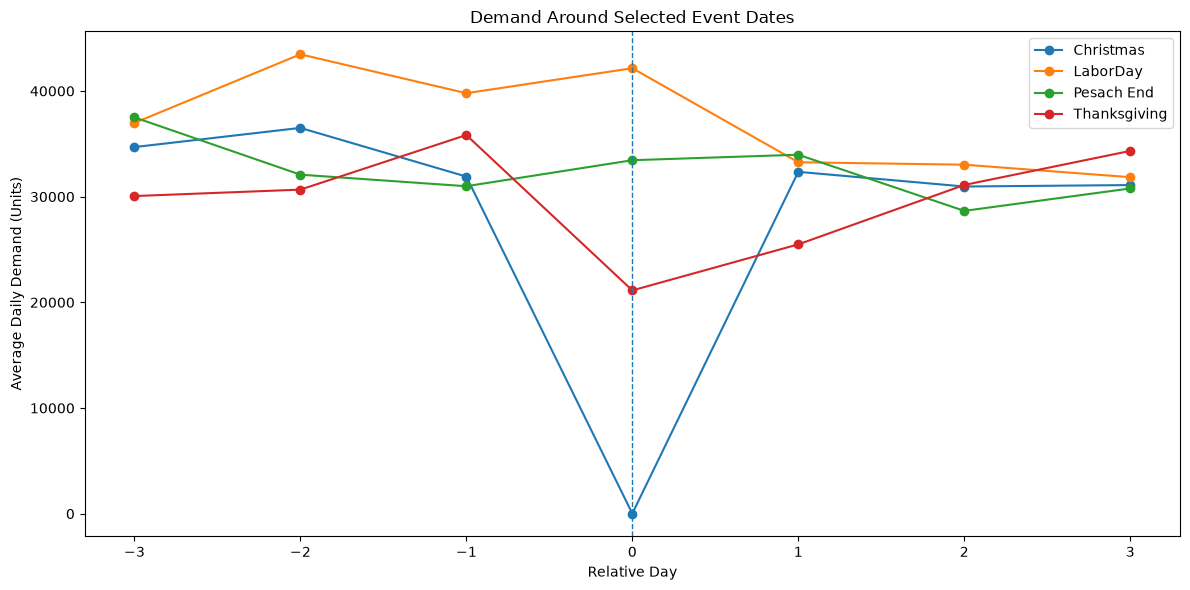

In [112]:
plt.figure(figsize=(12, 6))

for event in event_window_summary["event_name"].unique():
    event_data = event_window_summary[
        event_window_summary["event_name"] == event
    ]

    plt.plot(
        event_data["relative_day"],
        event_data["demand"],
        marker="o",
        label=event
    )

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Demand Around Selected Event Dates")
plt.xlabel("Relative Day")
plt.ylabel("Average Daily Demand (Units)")
plt.xticks(range(-3, 4))
plt.legend()
plt.tight_layout()
plt.show()

##### Demand Around Selected Events — Key Observations

- **Christmas** shows the most pronounced change, with average demand falling from approximately **31,900 units on Day -1 to only 16 units on the event day**, followed by a sharp recovery to approximately **32,349 units on Day +1**.
- **Thanksgiving** also shows a noticeable demand drop, from approximately **35,832 units on Day -1 to 21,130 units on the event day**, followed by gradual recovery over the next three days.
- **LaborDay** shows relatively high demand on the event day (**42,155 units**), followed by lower demand over the next three days.
- **Pesach End** shows a less consistent pattern, with demand around the event remaining within a broader range rather than showing a sharp event-day movement.
- Overall, the selected events show that demand can behave differently around different event dates, with some associated with sharp drops and others with relatively higher or more stable demand.
- These patterns represent **historical associations and do not establish that the events caused the changes**.

#### 4.1.3 Event Type Comparison

We now compare demand across different event types to determine whether demand patterns differ between broader event categories.

We will compare:
- Average daily demand
- Median daily demand
- Demand variability
- Average day-to-day demand change

**Business Question:**

> Do demand patterns differ across event types?

In [113]:
# Create event-type data

event_type_data = pd.concat([
    calendar[["date", "event_type_1"]].rename(
        columns={"event_type_1": "event_type"}
    ),
    calendar[["date", "event_type_2"]].rename(
        columns={"event_type_2": "event_type"}
    )
]).dropna()

event_type_data = event_type_data.merge(
    daily_demand[
        ["date", "demand", "demand_change"]
    ],
    on="date",
    how="left"
)

In [114]:
# Compare event types

event_type_summary = (
    event_type_data
    .groupby("event_type")
    .agg(
        event_days=("date", "nunique"),
        average_demand=("demand", "mean"),
        median_demand=("demand", "median"),
        demand_std=("demand", "std"),
        average_demand_change=("demand_change", "mean")
    )
    .reset_index()
    .sort_values("average_demand", ascending=False)
)

event_type_summary

,event_type,event_days,average_demand,median_demand,demand_std,average_demand_change
3,Sporting,18,35796.062500,34998.0,6651.926533,-4029.562500
0,Cultural,41,34419.236842,35454.5,7540.098262,-4384.236842
2,Religious,56,33858.301887,34003.0,7037.287594,-55.811321
1,National,52,29458.509804,32656.0,12117.064001,-8704.980392


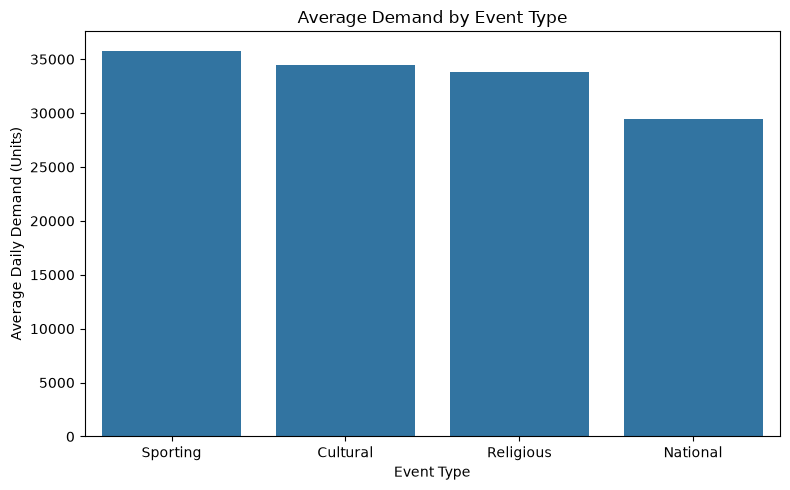

In [115]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=event_type_summary,
    x="event_type",
    y="average_demand"
)

plt.title("Average Demand by Event Type")
plt.xlabel("Event Type")
plt.ylabel("Average Daily Demand (Units)")
plt.tight_layout()
plt.show()

##### Event Type — Key Observations

- **Sporting events** had the highest average daily demand at approximately **35,796 units**, while **National events** had the lowest at approximately **29,459 units**.
- National events also showed the highest demand variability, with a standard deviation of approximately **12,117 units**.
- Average day-to-day demand change was negative for Sporting, Cultural, and National events, while Religious events were close to zero.
- This indicates that demand patterns differ across event types, particularly in **demand level and variability**.
- These results describe historical associations and do not establish that event type caused the observed demand differences.

### 4.2 Price Analysis

Price is an important potential demand driver in retail.

We will first examine the selling-price distribution and then analyze the relationship between price and demand after aligning both datasets at the appropriate product-store-day grain.

We will also examine demand around price changes.

**Business Question:**

> Are demand changes associated with changes in selling price?

#### 4.2.1 Selling Price Distribution

We first examine the distribution of selling prices to understand the typical price level and variation across products and stores.

We will examine:
- Minimum and maximum price
- Mean and median price
- Price variation
- Price distribution

In [116]:
price_summary = selling_prices["sell_price"].describe()

price_summary

count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

In [117]:
price_mean = selling_prices["sell_price"].mean()
price_std = selling_prices["sell_price"].std()

price_cv = (
    price_std / price_mean
) * 100

price_cv

np.float64(77.28067328608562)

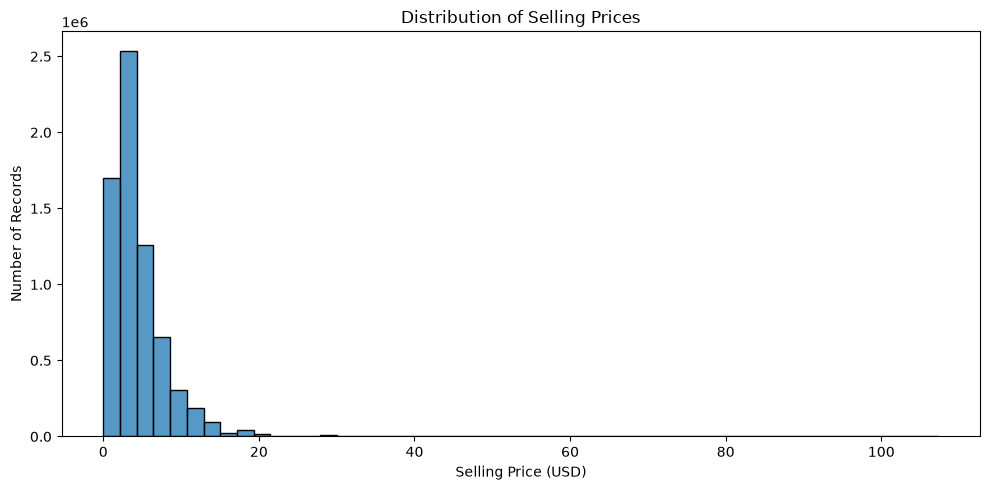

In [118]:
plt.figure(figsize=(10, 5))

sns.histplot(
    selling_prices["sell_price"],
    bins=50
)

plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price (USD)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

##### Selling Price — Key Observations

- The median selling price is **$3.47**, while the mean is **$4.41**, indicating that higher-priced products pull the average upward.
- The middle 50% of selling prices range from **$2.18 to $5.84**.
- Selling prices vary considerably, with a coefficient of variation of approximately **77.3%**.
- The price distribution is strongly right-skewed, with a relatively small number of products having much higher selling prices.

#### 4.2.2 Price vs Demand

We now examine the relationship between selling price and product demand.

Because selling prices are recorded at the **product × store × week** level while demand is recorded daily, the two datasets will first be aligned at the **product × store × day** level.

We will then use a scatter plot and correlation to examine the relationship between price and demand.

**Business Question:**

> Are demand levels associated with selling price?

In [119]:
# Align the daily demand with the weekly price

sales_historical = sales_historical.merge(
    calendar[["d", "wm_yr_wk"]],
    on="d",
    how="left"
)

In [120]:
sales_historical[
    ["item_id", "store_id", "d", "wm_yr_wk", "demand"]
].head(10)

,item_id,store_id,d,wm_yr_wk,demand
0,HOBBIES_1_001,CA_1,d_1,11101,0
1,HOBBIES_1_002,CA_1,d_1,11101,0
2,HOBBIES_1_003,CA_1,d_1,11101,0
3,HOBBIES_1_004,CA_1,d_1,11101,0
4,HOBBIES_1_005,CA_1,d_1,11101,0
5,HOBBIES_1_006,CA_1,d_1,11101,0
6,HOBBIES_1_007,CA_1,d_1,11101,0
7,HOBBIES_1_008,CA_1,d_1,11101,12
8,HOBBIES_1_009,CA_1,d_1,11101,2
9,HOBBIES_1_010,CA_1,d_1,11101,0


> item_id + store_id + d + wm_yr_wk + demand

In [121]:
sales_historical["wm_yr_wk"].isna().sum()

np.int64(0)

In [122]:
# aggregate demand to the price grain

weekly_product_demand = (
    sales_historical
    .groupby(["item_id", "store_id", "wm_yr_wk"])["demand"]
    .sum()
    .reset_index()
)

In [123]:
weekly_product_demand.shape

(8354260, 4)

In [124]:
# merge weekly demand with selling price

price_demand = weekly_product_demand.merge(
    selling_prices,
    on=["item_id", "store_id", "wm_yr_wk"],
    how="inner"
)

In [125]:
price_demand.shape

(6597201, 5)

In [126]:
price_demand.duplicated(
    subset=["item_id", "store_id", "wm_yr_wk"]
).sum()

np.int64(0)

> 1 row = 1 product × 1 store × 1 week

In [127]:
price_demand[
    ["item_id", "store_id", "wm_yr_wk", "demand", "sell_price"]
].isna().sum()

item_id       0
store_id      0
wm_yr_wk      0
demand        0
sell_price    0
dtype: int64

In [128]:
# calculate the price-demand correlation

price_demand[["sell_price", "demand"]].corr()

,sell_price,demand
sell_price,1.00000,-0.17313
demand,-0.17313,1.00000


In [129]:
price_demand_sample = price_demand.sample(
    n=100000,
    random_state=42
)

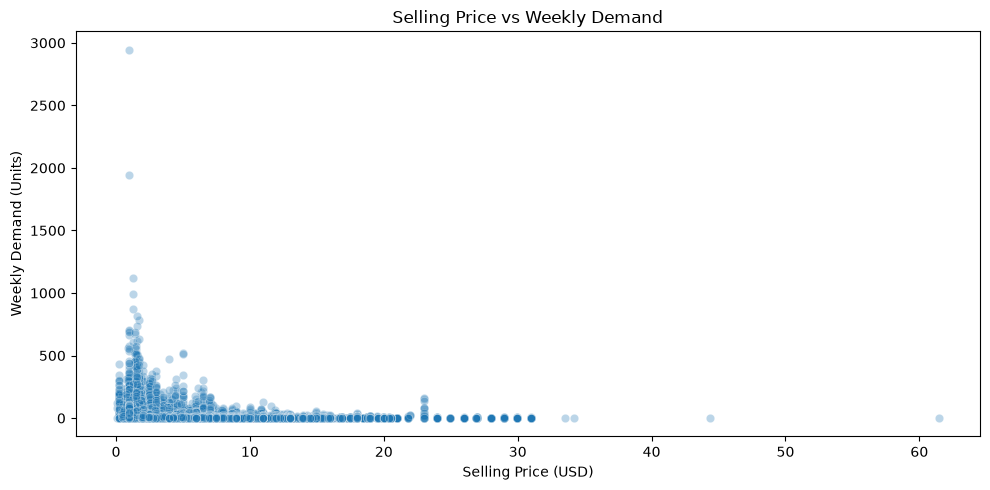

In [130]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=price_demand_sample,
    x="sell_price",
    y="demand",
    alpha=0.3
)

plt.title("Selling Price vs Weekly Demand")
plt.xlabel("Selling Price (USD)")
plt.ylabel("Weekly Demand (Units)")
plt.tight_layout()
plt.show()

##### Price vs Demand — Key Observations

- Selling price and weekly demand show a **weak negative correlation of -0.173** across the merged product-store-week dataset.
- The scatter plot shows a large concentration of observations at low demand levels, with no clear strong linear relationship between price and demand.
- The overall relationship is influenced by differences between products and stores, since products have different baseline demand levels and price ranges.
- Therefore, the overall price-demand relationship should be treated as a **descriptive association**, not evidence that price changes caused changes in demand.

#### 4.2.3 Price Changes

We now examine demand around weeks where the selling price changed for the same product and store.

We will compare:

- Demand before the price change
- Demand after the price change
- Direction and size of demand movement

**Business Question:**

> Are demand changes associated with changes in selling price?

In [131]:
price_demand["previous_price"] = (
    price_demand
    .sort_values(["item_id", "store_id", "wm_yr_wk"])
    .groupby(["item_id", "store_id"])["sell_price"]
    .shift(1)
)

price_demand["price_changed"] = (
    price_demand["sell_price"] != price_demand["previous_price"]
)

In [132]:
price_demand["price_changed"].value_counts()

price_changed
False    6489508
True      107693
Name: count, dtype: int64

In [133]:
price_changes = price_demand[
    price_demand["price_changed"]
].copy()

In [134]:
price_changes.shape

(107693, 7)

In [135]:
price_changes.columns

Index(['item_id', 'store_id', 'wm_yr_wk', 'demand', 'sell_price',
       'previous_price', 'price_changed'],
      dtype='str')

In [136]:
# calculate the price movement

price_changes["price_change"] = (
    price_changes["sell_price"]
    - price_changes["previous_price"]
)

In [137]:
price_changes[
    ["previous_price", "sell_price", "price_change"]
].head(10)

,previous_price,sell_price,price_change
0,NaN,2.00,NaN
83,2.00,2.24,0.24
274,NaN,2.00,NaN
357,2.00,2.24,0.24
548,NaN,2.00,NaN
586,2.00,1.75,-0.25
587,1.75,2.00,0.25
631,2.00,2.24,0.24
693,2.24,2.00,-0.24
705,2.00,2.24,0.24


In [138]:
# remove rows without a previous price

price_changes = price_changes[
    price_changes["previous_price"].notna()
].copy()

In [139]:
price_changes.shape

(77203, 8)

In [140]:
# classify price changes

price_changes["price_change_type"] = np.where(
    price_changes["price_change"] > 0,
    "Increase",
    "Decrease"
)

In [141]:
price_changes["price_change_type"].value_counts()

price_change_type
Increase    44298
Decrease    32905
Name: count, dtype: int64

In [142]:
# calculate demand change

price_changes = price_changes.sort_values(
    ["item_id", "store_id", "wm_yr_wk"]
)

price_changes["previous_demand"] = (
    price_changes
    .groupby(["item_id", "store_id"])["demand"]
    .shift(1)
)

In [143]:
price_changes[
    ["item_id", "store_id", "wm_yr_wk",
     "previous_price", "sell_price",
     "previous_demand", "demand"]
].head(10)

,item_id,store_id,wm_yr_wk,previous_price,sell_price,previous_demand,demand
83,FOODS_1_001,CA_1,11232,2.00,2.24,NaN,9
357,FOODS_1_001,CA_2,11232,2.00,2.24,NaN,8
586,FOODS_1_001,CA_3,11139,2.00,1.75,NaN,2
587,FOODS_1_001,CA_3,11140,1.75,2.00,2.0,11
631,FOODS_1_001,CA_3,11232,2.00,2.24,11.0,9
693,FOODS_1_001,CA_3,11342,2.24,2.00,9.0,3
705,FOODS_1_001,CA_3,11401,2.00,2.24,3.0,18
905,FOODS_1_001,CA_4,11232,2.00,2.24,NaN,3
1148,FOODS_1_001,TX_1,11201,2.00,1.19,NaN,5
1149,FOODS_1_001,TX_1,11202,1.19,2.00,5.0,3


In [144]:
price_changes = price_changes[
    price_changes["previous_demand"].notna()
].copy()

In [145]:
price_changes.shape

(55084, 10)

In [146]:
# calculate demand movement

price_changes["demand_change"] = (
    price_changes["demand"]
    - price_changes["previous_demand"]
)

In [147]:
price_changes["demand_change_pct"] = np.where(
    price_changes["previous_demand"] > 0,
    (
        price_changes["demand_change"]
        / price_changes["previous_demand"]
    ) * 100,
    np.nan
)

In [148]:
price_changes[
    ["price_change_type", "previous_price", "sell_price",
     "previous_demand", "demand",
     "demand_change", "demand_change_pct"]
].head(10)

,price_change_type,previous_price,sell_price,previous_demand,demand,demand_change,demand_change_pct
587,Increase,1.75,2.00,2.0,11,9.0,450.000000
631,Increase,2.00,2.24,11.0,9,-2.0,-18.181818
693,Decrease,2.24,2.00,9.0,3,-6.0,-66.666667
705,Increase,2.00,2.24,3.0,18,15.0,500.000000
1149,Increase,1.19,2.00,5.0,3,-2.0,-40.000000
1161,Decrease,2.00,1.00,3.0,7,4.0,133.333333
1162,Increase,1.00,2.00,7.0,6,-1.0,-14.285714
1179,Increase,2.00,2.24,6.0,9,3.0,50.000000
1193,Decrease,2.24,1.99,9.0,1,-8.0,-88.888889
1194,Increase,1.99,2.24,1.0,3,2.0,200.000000


In [149]:
# compare demand movement by price-change direction

price_change_summary = (
    price_changes
    .groupby("price_change_type")["demand_change"]
    .agg(
        average_demand_change="mean",
        median_demand_change="median",
        demand_change_std="std"
    )
    .reset_index()
)

price_change_summary

,price_change_type,average_demand_change,median_demand_change,demand_change_std
0,Decrease,-1.047630,0.0,26.763610
1,Increase,0.213475,0.0,25.599988


In [150]:
# compare the direction of demand movement

price_changes["demand_change_type"] = np.select(
    [
        price_changes["demand_change"] > 0,
        price_changes["demand_change"] < 0
    ],
    [
        "Increase",
        "Decrease"
    ],
    default="No Change"
)

In [151]:
demand_direction_summary = (
    price_changes
    .groupby(["price_change_type", "demand_change_type"])
    .size()
    .reset_index(name="count")
)

demand_direction_summary["percentage"] = (
    demand_direction_summary["count"]
    / demand_direction_summary
        .groupby("price_change_type")["count"]
        .transform("sum")
) * 100

demand_direction_summary

,price_change_type,demand_change_type,count,percentage
0,Decrease,Decrease,10928,48.238722
1,Decrease,Increase,8973,39.608899
2,Decrease,No Change,2753,12.152379
3,Increase,Decrease,13329,41.100833
4,Increase,Increase,14853,45.800185
5,Increase,No Change,4248,13.098982


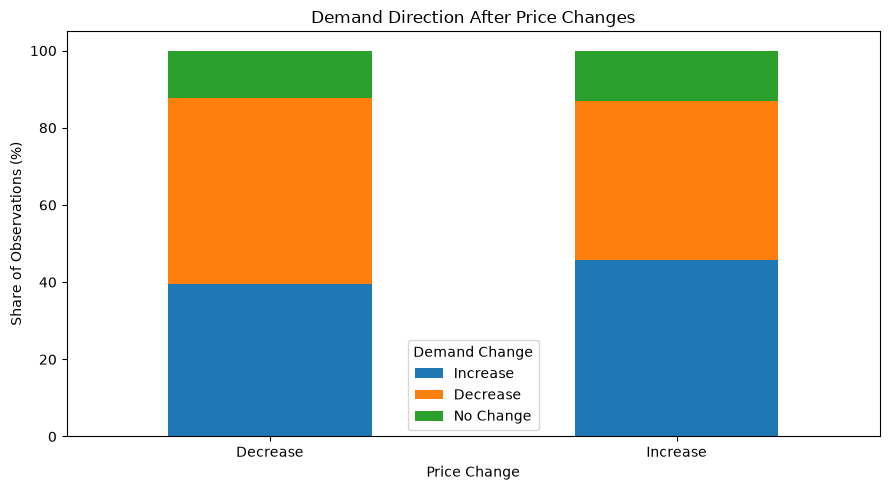

In [152]:
demand_direction_pivot = (
    demand_direction_summary
    .pivot(
        index="price_change_type",
        columns="demand_change_type",
        values="percentage"
    )
)

demand_direction_pivot = demand_direction_pivot[
    ["Increase", "Decrease", "No Change"]
]

demand_direction_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Demand Direction After Price Changes")
plt.xlabel("Price Change")
plt.ylabel("Share of Observations (%)")
plt.xticks(rotation=0)
plt.legend(title="Demand Change")
plt.tight_layout()
plt.show()

##### Price Changes — Key Observations

- When prices decreased, demand decreased in **48.2%** of observations and increased in **39.6%**.
- When prices increased, demand increased in **45.8%** of observations and decreased in **41.1%**.
- Demand showed no change in approximately **12–13%** of observations for both price-change directions.
- The results do not show a consistent inverse relationship between price changes and demand changes across all product-store observations.
- This suggests that demand movements around price changes are influenced by factors beyond the price change itself.
- These results represent **historical associations and do not establish that price changes caused the observed demand movements**.

## 5. Product × Store Demand

We now examine whether the same products show different demand patterns across stores.

This analysis will help determine whether **Product × Store** is an appropriate level for demand forecasting.

**Business Question:**

> Does the same product behave differently across stores?

In [153]:
product_store_demand = (
    sales_historical
    .groupby(["item_id", "store_id"])["demand"]
    .mean()
    .reset_index(name="average_daily_demand")
)

> 1 row = 1 product × 1 store

In [154]:
product_store_demand.shape

(30490, 3)

In [155]:
product_store_variation = (
    product_store_demand
    .groupby("item_id")["average_daily_demand"]
    .agg(
        min_store_demand="min",
        max_store_demand="max"
    )
    .reset_index()
)

product_store_variation["store_demand_range"] = (
    product_store_variation["max_store_demand"]
    - product_store_variation["min_store_demand"]
)

In [156]:
product_store_variation["store_demand_range"].describe()

count    3049.000000
mean        1.900751
std         4.394524
min         0.030842
25%         0.335599
50%         0.774177
75%         1.759017
max       114.182436
Name: store_demand_range, dtype: float64

In [157]:
product_store_variation["relative_store_difference_pct"] = np.where(
    product_store_variation["min_store_demand"] > 0,
    (
        (
            product_store_variation["max_store_demand"]
            - product_store_variation["min_store_demand"]
        )
        / product_store_variation["min_store_demand"]
    ) * 100,
    np.nan
)

In [158]:
product_store_variation[
    "relative_store_difference_pct"
].describe()

count     3049.000000
mean       638.888325
std       1185.609793
min         61.492211
25%        263.118995
50%        401.154250
75%        637.825716
max      34603.225806
Name: relative_store_difference_pct, dtype: float64

In [159]:
# compare the same products across stores

product_store_cv = (
    product_store_demand
    .groupby("item_id")["average_daily_demand"]
    .agg(
        mean_store_demand="mean",
        std_store_demand="std"
    )
    .reset_index()
)

product_store_cv["store_cv_pct"] = (
    product_store_cv["std_store_demand"]
    / product_store_cv["mean_store_demand"]
) * 100

In [160]:
product_store_cv["store_cv_pct"].describe()

count    3049.000000
mean       51.589605
std        16.785496
min        16.434166
25%        40.197383
50%        49.021364
75%        60.024622
max       173.297603
Name: store_cv_pct, dtype: float64

##### Product × Store — Key Observations

- Demand varies across stores for the same product, with a median store-level coefficient of variation of approximately **49.0%** across the 3,049 products.
- The variation indicates that products do not have identical demand levels across stores.
- This suggests that store-level differences are important when forecasting product demand.
- Therefore, **Product × Store** is a meaningful level to consider for demand forecasting.

## 6. Product × Store × Time

We now examine how demand changes over time for individual product-store combinations.

This helps determine whether Product × Store × Time is an appropriate level for demand forecasting.

**Business Question:**

> Does demand for the same product-store combination change over time?

In [161]:
# create a monthly Product × Store demand table

product_store_monthly = (
    sales_historical
    .merge(
        calendar[["d", "month", "year"]],
        on="d",
        how="left"
    )
)

In [162]:
product_store_monthly = (
    product_store_monthly
    .groupby(
        ["item_id", "store_id", "year", "month"]
    )["demand"]
    .sum()
    .reset_index()
)

> 1 row = 1 Product × 1 Store × 1 Year × 1 Month

In [163]:
product_store_monthly.shape

(1951360, 5)

In [164]:
product_store_monthly.duplicated(
    subset=["item_id", "store_id", "year", "month"]
).sum()

np.int64(0)

In [165]:
product_store_monthly.head()

,item_id,store_id,year,month,demand
0,FOODS_1_001,CA_1,2011,1,3
1,FOODS_1_001,CA_1,2011,2,40
2,FOODS_1_001,CA_1,2011,3,40
3,FOODS_1_001,CA_1,2011,4,23
4,FOODS_1_001,CA_1,2011,5,50


In [166]:
# calculate demand change over time

product_store_monthly = product_store_monthly.sort_values(
    ["item_id", "store_id", "year", "month"]
)

In [167]:
product_store_monthly["demand_change"] = (
    product_store_monthly
    .groupby(["item_id", "store_id"])["demand"]
    .diff()
)

In [168]:
product_store_monthly["demand_change"].describe()

count    1.920870e+06
mean     4.990057e-01
std      4.012894e+01
min     -5.936000e+03
25%     -3.000000e+00
50%      0.000000e+00
75%      3.000000e+00
max      6.150000e+03
Name: demand_change, dtype: float64

In [169]:
top_product_store = (
    product_store_monthly
    .groupby(["item_id", "store_id"])["demand"]
    .sum()
    .reset_index()
    .sort_values("demand", ascending=False)
    .head(1)
)

top_product_store

,item_id,store_id,demand
7022,FOODS_3_090,CA_3,250502


In [170]:
# monthly demand trend

top_product_store_id = top_product_store.iloc[0]["item_id"]
top_product_store_store = top_product_store.iloc[0]["store_id"]

top_product_store_trend = product_store_monthly[
    (product_store_monthly["item_id"] == top_product_store_id) &
    (product_store_monthly["store_id"] == top_product_store_store)
].copy()

top_product_store_trend["year_month"] = (
    top_product_store_trend["year"].astype(str)
    + "-"
    + top_product_store_trend["month"].astype(str).str.zfill(2)
)

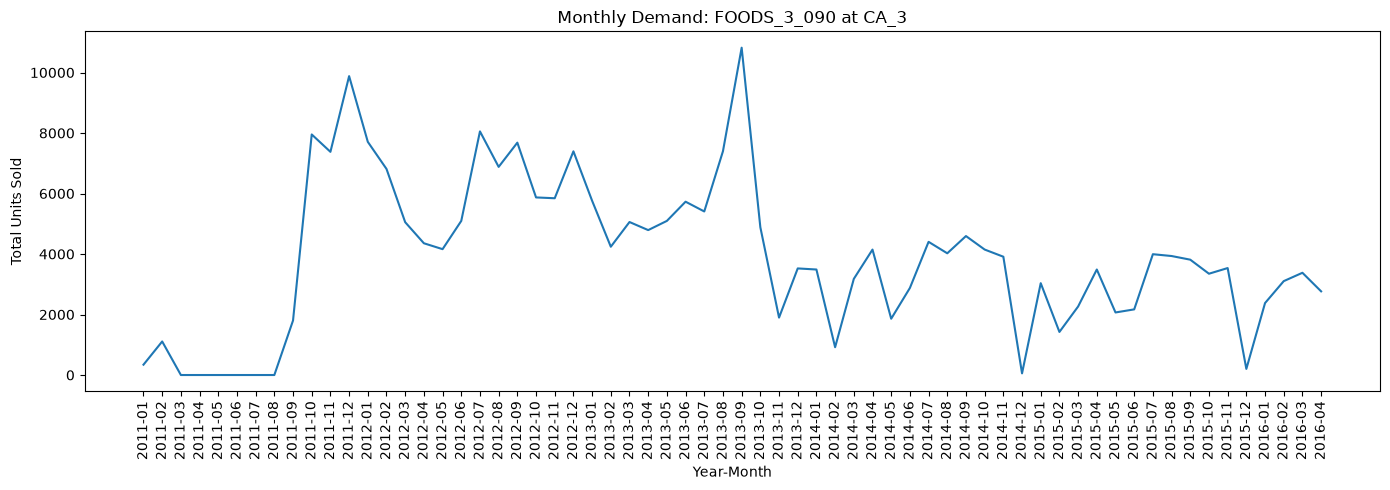

In [171]:
plt.figure(figsize=(14, 5))

plt.plot(
    top_product_store_trend["year_month"],
    top_product_store_trend["demand"]
)

plt.title(
    f"Monthly Demand: {top_product_store_id} at {top_product_store_store}"
)
plt.xlabel("Year-Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [172]:
# use 3 representative Product × Store combinations

product_store_total = (
    product_store_monthly
    .groupby(["item_id", "store_id"])["demand"]
    .sum()
    .reset_index(name="total_demand")
)

product_store_total["demand_group"] = pd.qcut(
    product_store_total["total_demand"],
    q=3,
    labels=["Low", "Medium", "High"]
)

In [173]:
representative_product_stores = (
    product_store_total
    .groupby("demand_group", observed=True)
    .apply(
        lambda x: x.iloc[len(x) // 2],
        include_groups=False
    )
    .reset_index()
)

representative_product_stores

,demand_group,item_id,store_id,total_demand
0,Low,HOBBIES_2_051,WI_3,293
1,Medium,HOBBIES_1_079,WI_2,1109
2,High,FOODS_3_513,TX_2,2929


In [174]:
# monthly demand patterns over time

representative_trends = product_store_monthly.merge(
    representative_product_stores[
        ["demand_group", "item_id", "store_id"]
    ],
    on=["item_id", "store_id"],
    how="inner"
)

representative_trends["year_month"] = (
    representative_trends["year"].astype(str)
    + "-"
    + representative_trends["month"].astype(str).str.zfill(2)
)

representative_trends = representative_trends.sort_values(
    ["demand_group", "year", "month"]
)

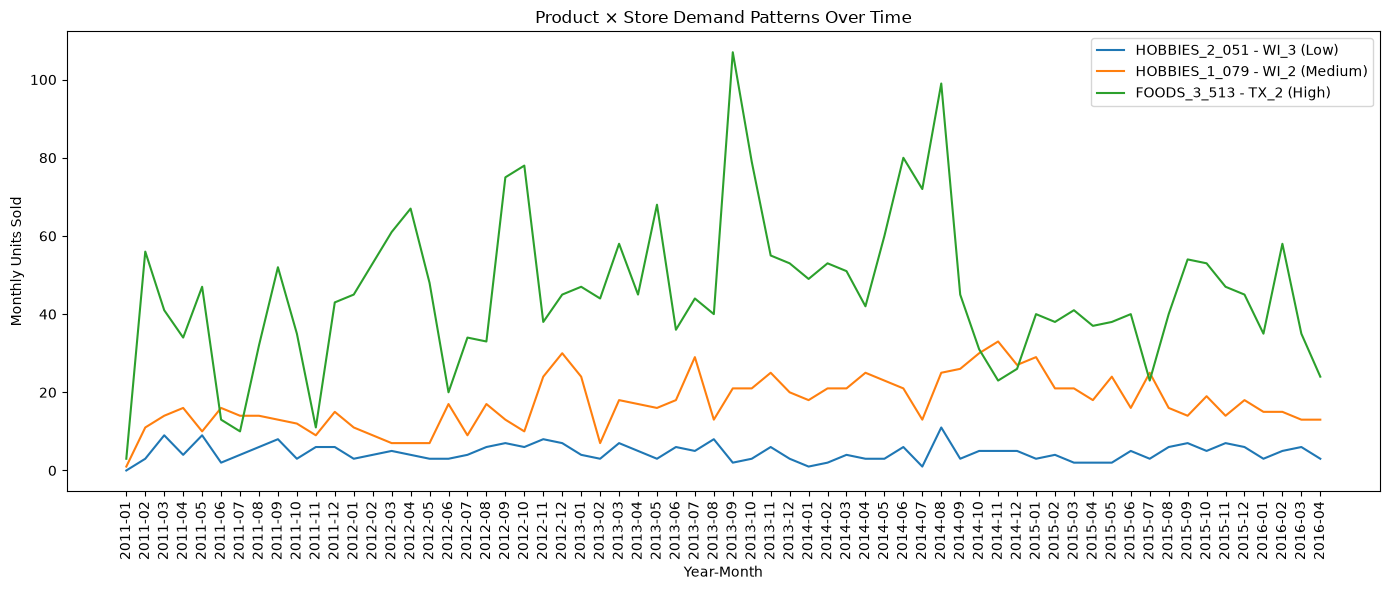

In [175]:
plt.figure(figsize=(14, 6))

for group in ["Low", "Medium", "High"]:
    data = representative_trends[
        representative_trends["demand_group"] == group
    ]

    label = (
        f"{data['item_id'].iloc[0]} - "
        f"{data['store_id'].iloc[0]} ({group})"
    )

    plt.plot(
        data["year_month"],
        data["demand"],
        label=label
    )

plt.title("Product × Store Demand Patterns Over Time")
plt.xlabel("Year-Month")
plt.ylabel("Monthly Units Sold")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()

##### Product × Store × Time — Key Observations

- Demand patterns differ across Product × Store combinations and change over time.
- The representative combinations show different demand levels and different degrees of fluctuation across the historical period.
- This indicates that demand should not be treated as identical across products or stores, and historical time patterns should be considered when forecasting.
- Therefore, **Product × Store** will be used as the forecasting grain, with **Time as the forecasting dimension**.

## 7. Product × Store Demand Intermittency

The Product × Store volatility analysis showed very high CV values for many combinations.

We therefore examine how frequently Product × Store combinations have zero-demand days.

We will compare:

- Zero-demand days
- Non-zero-demand days
- Percentage of zero-demand days

**Business Question:**

> How common is intermittent demand across Product × Store combinations?

In [176]:
# calculate zero-demand frequency for each Product × Store combination

product_store_intermittency = (
    sales_historical
    .groupby(["item_id", "store_id"])["demand"]
    .agg(
        total_days="count",
        zero_demand_days=lambda x: (x == 0).sum(),
        non_zero_demand_days=lambda x: (x > 0).sum()
    )
    .reset_index()
)

In [177]:
product_store_intermittency["zero_demand_pct"] = (
    product_store_intermittency["zero_demand_days"]
    / product_store_intermittency["total_days"]
) * 100

In [178]:
product_store_intermittency["zero_demand_pct"].describe()

count    30490.000000
mean        68.196276
std         22.377330
min          0.156822
25%         53.685311
50%         73.549399
75%         86.722426
max         99.634083
Name: zero_demand_pct, dtype: float64

##### Product × Store Demand Intermittency — Key Observations

- The median Product × Store combination has approximately **73.5% zero-demand days**.
- The middle 50% of combinations have approximately **53.7%–86.7% zero-demand days**.
- This shows that many Product × Store combinations have intermittent demand rather than continuous daily demand.
- The high frequency of zero-demand observations also helps explain the very high Product × Store CV values observed earlier.
- Intermittent demand should therefore be considered when selecting and evaluating the forecasting approach.

## 8. Demand Volatility

We now examine how stable or variable demand is across different parts of the business.

We will compare demand variability at the:

- Product level
- Product × Store level
- Category level
- Store level

**Business Question:**

> Which parts of the business have stable demand and which have highly variable demand?

#### Product-level volatility

In [179]:
product_volatility = (
    product_daily_demand
    .groupby("item_id")["demand"]
    .agg(
        average_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

product_volatility["cv_pct"] = (
    product_volatility["demand_std"]
    / product_volatility["average_demand"]
) * 100

In [180]:
product_volatility["cv_pct"].describe()

count    3049.000000
mean      102.681388
std        47.665828
min        21.379754
25%        66.672325
50%        90.504396
75%       128.729791
max       397.821328
Name: cv_pct, dtype: float64

#### Product × Store volatility

In [181]:
product_store_volatility = (
    sales_historical
    .groupby(["item_id", "store_id"])["demand"]
    .agg(
        average_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

product_store_volatility["cv_pct"] = (
    product_store_volatility["demand_std"]
    / product_store_volatility["average_demand"]
) * 100

In [182]:
product_store_volatility["cv_pct"].describe()

count    30490.000000
mean       238.633369
std        131.434250
min         25.313216
25%        145.923170
50%        204.918459
75%        297.033056
max       2303.269802
Name: cv_pct, dtype: float64

#### Category-level volatility

In [183]:
category_volatility = (
    category_daily_demand
    .groupby("cat_id")["demand"]
    .agg(
        average_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

category_volatility["cv_pct"] = (
    category_volatility["demand_std"]
    / category_volatility["average_demand"]
) * 100

In [184]:
category_volatility

,cat_id,average_demand,demand_std,cv_pct
0,FOODS,23570.276529,4908.505905,20.824982
1,HOBBIES,3201.672765,706.371092,22.062564
2,HOUSEHOLD,7569.613173,2194.630349,28.992635


#### Store-level volatility

In [185]:
store_volatility = (
    store_daily_demand
    .groupby("store_id")["demand"]
    .agg(
        average_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

store_volatility["cv_pct"] = (
    store_volatility["demand_std"]
    / store_volatility["average_demand"]
) * 100

In [186]:
store_volatility

,store_id,average_demand,demand_std,cv_pct
0,CA_1,4024.158913,991.847206,24.647317
1,CA_2,2972.020387,900.059626,30.284436
2,CA_3,5848.499739,1200.731543,20.530591
3,CA_4,2145.152117,427.928177,19.948617
4,TX_1,2924.878202,614.763981,21.018447
5,TX_2,3771.240983,792.894722,21.024769
6,TX_3,3183.131208,681.376424,21.405854
7,WI_1,2691.616309,997.253859,37.050372
8,WI_2,3420.811291,1284.960834,37.563044
9,WI_3,3360.053319,825.531851,24.569010


##### Demand Volatility — Key Observations

- Demand variability differs substantially across products, with a median product-level CV of approximately **90.5%**.
- Product × Store volatility is considerably higher, with a median CV of approximately **204.9%**. However, this measure should be interpreted cautiously because low average demand can produce very high CV values.
- At the category level, **HOUSEHOLD has the highest relative variability** at approximately **29.0%**, compared with 20.8% for FOODS and 22.1% for HOBBIES.
- At the store level, **WI_2 and WI_1 show the highest relative variability**, at approximately **37.6% and 37.1%** respectively.
- These differences indicate that forecast difficulty may vary across products, categories, and stores.

## 9. SNAP Analysis

SNAP indicators identify days when SNAP benefits were active in California, Texas, and Wisconsin.

This analysis examines whether demand differed between SNAP-active and non-SNAP days across the three states.

In [187]:
state_daily_demand = (
    sales_historical
    .groupby(["store_id", "d"], as_index=False)["demand"]
    .sum()
)

store_state = (
    sales_historical[
        ["store_id", "state_id"]
    ]
    .drop_duplicates()
)

state_daily_demand = state_daily_demand.merge(
    store_state,
    on="store_id",
    how="left"
)

state_daily_demand = (
    state_daily_demand
    .groupby(["state_id", "d"], as_index=False)["demand"]
    .sum()
    .rename(columns={"demand": "state_demand"})
)

state_daily_demand.head()

,state_id,d,state_demand
0,CA,d_1,14195
1,CA,d_10,11822
2,CA,d_100,11231
3,CA,d_1000,13066
4,CA,d_1001,14957


In [188]:
state_daily_demand = state_daily_demand.merge(
    calendar[
        ["d", "snap_CA", "snap_TX", "snap_WI"]
    ],
    on="d",
    how="left"
)

state_daily_demand["SNAP_Active"] = np.select(
    [
        state_daily_demand["state_id"] == "CA",
        state_daily_demand["state_id"] == "TX",
        state_daily_demand["state_id"] == "WI"
    ],
    [
        state_daily_demand["snap_CA"],
        state_daily_demand["snap_TX"],
        state_daily_demand["snap_WI"]
    ],
    default=np.nan
)

state_daily_demand.head()

,state_id,d,state_demand,snap_CA,snap_TX,snap_WI,SNAP_Active
0,CA,d_1,14195,0,0,0,0.0
1,CA,d_10,11822,1,1,0,1.0
2,CA,d_100,11231,1,0,1,1.0
3,CA,d_1000,13066,0,0,0,0.0
4,CA,d_1001,14957,0,0,0,0.0


In [189]:
snap_demand_summary = (
    state_daily_demand
    .groupby(["state_id", "SNAP_Active"])["state_demand"]
    .agg(
        Average_Daily_Demand="mean",
        Total_Demand="sum",
        Days="count"
    )
    .reset_index()
)

snap_demand_summary

,state_id,SNAP_Active,Average_Daily_Demand,Total_Demand,Days
0,CA,0.0,14605.813718,18739259,1283
1,CA,1.0,15771.885714,9936288,630
2,TX,0.0,9519.082619,12212983,1283
3,TX,1.0,10612.734921,6686023,630
4,WI,0.0,8838.505066,11339802,1283
5,WI,1.0,10763.577778,6781054,630


In [190]:
snap_demand_comparison = (
    snap_demand_summary
    .pivot(
        index="state_id",
        columns="SNAP_Active",
        values="Average_Daily_Demand"
    )
    .reset_index()
)

snap_demand_comparison.columns = [
    "state_id",
    "Non_SNAP_Demand",
    "SNAP_Demand"
]

snap_demand_comparison["Demand_Difference_Pct"] = (
    (
        snap_demand_comparison["SNAP_Demand"]
        - snap_demand_comparison["Non_SNAP_Demand"]
    )
    / snap_demand_comparison["Non_SNAP_Demand"]
) * 100

snap_demand_comparison

,state_id,Non_SNAP_Demand,SNAP_Demand,Demand_Difference_Pct
0,CA,14605.813718,15771.885714,7.983615
1,TX,9519.082619,10612.734921,11.489051
2,WI,8838.505066,10763.577778,21.780524


## Demand Analysis Conclusion

The historical demand analysis identified several patterns that are relevant to demand forecasting and subsequent forecast-error analysis.

| Demand Pattern | Finding | Relevance to Forecasting |
|---|---|---|
| Overall demand trend | Overall demand showed an upward trend over the historical period, with variation across years. | Recent demand levels may provide useful information for short-term forecasting. |
| Weekly pattern | Weekend demand was approximately 31% higher than weekday demand. | Supports testing forecasting methods that account for weekly demand patterns. |
| Within-month pattern | Demand was higher at the beginning of the month and declined toward the end. | Indicates a potential calendar-related demand pattern to consider during error analysis. |
| Product mix | FOODS contributed 68.6% of total demand, followed by HOUSEHOLD at 22.0% and HOBBIES at 9.3%. | Forecast performance may differ across product categories because demand volumes and patterns differ. |
| Product concentration | The highest-demand 25% of products accounted for approximately 72.3% of total demand. | Forecast error should be examined across both high-volume and lower-volume products. |
| Store / state demand | Demand volume varied across states and individual stores. | Forecast performance may differ by geographic location. |
| Event periods | Event days showed different demand variability from non-event days, but average demand was not consistently higher. | Event periods should be examined as a potential source of forecast error rather than assumed to increase demand. |
| Price relationship | Product × Store × Week selling price showed a weak negative correlation with demand (−0.173). | Price may be examined as a potential error characteristic, but a strong linear relationship was not observed. |
| Demand volatility | Demand variability differed substantially across products and Product × Store series. | Higher volatility may be associated with greater forecasting difficulty. |
| Intermittency | Product × Store demand was highly intermittent, with a median of approximately 73.5% zero-demand days. | Intermittent demand may contribute to large percentage forecast errors and should be examined further. |
| Product × Store differences | Demand patterns varied across Product × Store combinations. | Product × Store is an appropriate forecasting grain and should remain central to error analysis. |
| SNAP periods   | Average daily demand was higher on SNAP-active days than non-SNAP days in all three states: CA +7.98%, TX +11.49%, and WI +21.78%. | SNAP periods may represent a different demand environment and can be examined as a potential factor associated with forecast error. |


### Overall Conclusion

The demand analysis shows that retail demand is not uniform across time, products, stores, or demand series. Weekly patterns, product concentration, geographic differences, volatility, and high demand intermittency were particularly relevant characteristics for the forecasting analysis.

These historical patterns provide hypotheses for the forecast-error analysis. The next analysis will examine whether characteristics such as demand volume, intermittency, volatility, time patterns, events, and price are associated with higher forecast error during the unseen evaluation period.